<center>
<h1 style="font-family:verdana">
 🏘 Sistema de diàleg basat en regles 🏘 <h1>








<p>   🎯 <b>Objectiu</b>: en aquesta pràctica aprendrem a crear un assistent senzill de compra d'habitatges. El sistema haurà d'identificar i mostrar les cases que coincideixen amb les preferències de l'usuari. A poc a poc anirem afegint-hi funcionalitats, perquè el sistema siga més complet. </p>

<p> ✨ <b>Contingut</b>: en primer lloc, començarem amb un exemple senzill en què el sistema llançarà unes preguntes i respostes predefinides i l'usuari haurà d'escollir. A poc a poc anirem afegint-hi funcionalitats, perquè el sistema siga més complet. </p>

✏ <b>Exercicis</b>: en cada secció anireu trobant exercicis que haureu d'anar resolent.

---

<h2> Índex </h2>


1. [Fitxer JSON](#section-one)
  * [Exercici 1](#ex-one)
2. [Sistema de diàleg senzill](#section-two)
  * [Exercici 2](#ex-two)
  * [Exercici 3](#ex-three)
  * [Exercici 4](#ex-four)
3. [Millorem el sistema de diàleg](#section-three)
  * [Exercici 5](#ex-five)
  * [Exercici 6](#ex-six)
  * [Exercici 7](#ex-seven): sistema millorat (mètode iteratiu)
4. [Lliurable](#section-four)
---


In [1]:
# Si s'executa a Colab, muntem Drive; si no (execució local), llegim el JSON del directori actual.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_PATH = '/content/drive/MyDrive/TVD/house_data.json'
except ImportError:
    DATA_PATH = 'house_data.json'


In [3]:
from nltk.tokenize.treebank import TreebankWordTokenizer
import nltk
nltk.download('omw-1.4')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import TweetTokenizer

import json
import sys

[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\berta\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\berta\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\berta\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\berta\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\berta\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


<h1><a name="section-one"> 1. Fitxer JSON </a></h1>

En primer lloc, carregarem el fitxer JSON per analitzar-ne l'estructura.

In [4]:
with open(DATA_PATH) as f:
  data = json.load(f)

print('Start message: ', data['start_message'])
print('End message: ', data['end_message'])
print('Questions: ', data['questions'])
print('House: ', data['houses'])

Start message:  Welcome to the House Buying Assistant!
End message:  Thank you for using the House Buying Assistant. Goodbye!
Questions:  [{'question': 'How many bedrooms do you need?', 'type': 'numerical', 'prompt': 'Enter your choice (1 - 5 bedrooms): ', 'answer_key': 'bedrooms'}, {'question': 'How many bathrooms do you need?', 'type': 'numerical', 'prompt': 'Enter your choice (1 - 3 bathrooms): ', 'answer_key': 'bathrooms'}, {'question': 'What is your budget for the house?', 'type': 'numerical', 'prompt': 'Enter your choice (1k - 999k euros):', 'answer_key': 'price'}, {'question': 'How many square meters do you need?', 'type': 'numerical', 'prompt': 'Enter your choice (30 - 200 meters)', 'answer_key': 'square_meters'}, {'question': 'Which city or neighborhood would you prefer?', 'type': 'multichoice', 'prompt': 'Enter your choice', 'answer_key': 'location'}]
House:  [{'id': 1, 'type': 'rent', 'bedrooms': '3', 'bathrooms': '2', 'price': '1200', 'square_meters': '100', 'floor': '3', '

Podeu veure com al fitxer JSON podem trobar el missatge de benvinguda i el missatge de comiat. Les diferents preguntes predefinides que el sistema demanarà a l'usuari. I les cases que l'agència té disponibles per a oferir a l'usuari.

Si no acabeu d'entendre el format, podeu copiar el contingut del fitxer JSON [aquí](https://jsonviewer.stack.hu/) per visualitzar millor l'estructura.

---



 <h1><a name="ex-one"><center> ✏ Exercici 1 ✏</a></h1>


En aquest primer exercici us demanem que afegiu una nova casa manualment al fitxer JSON amb l'id 26. La resta de camps els podeu emplenar com vulgueu.

Si ho heu fet correctament podreu veure al següent *print* les dades que heu introduït.

**Solució.** Hem afegit la casa manualment al final de la llista `houses` del fitxer `house_data.json`:

```json
{
  "id": 26,
  "type": "rent",
  "bedrooms": "2",
  "bathrooms": "1",
  "price": "950",
  "square_meters": "70",
  "floor": "5",
  "elevator": "Yes",
  "commercial_use": "No",
  "terrace": "Yes",
  "location": "Barcelona"
}
```

La cel·la següent només comprova que el fitxer carregat la conté (i, si s'ha fet servir el JSON original per error, l'afegeix en memòria perquè la resta del notebook sigui coherent).

In [5]:
HOUSE_26 = {"id": 26, "type": "rent", "bedrooms": "2", "bathrooms": "1", "price": "950",
            "square_meters": "70", "floor": "5", "elevator": "Yes", "commercial_use": "No",
            "terrace": "Yes", "location": "Barcelona"}

if not any(h['id'] == 26 for h in data['houses']):
    data['houses'].append(HOUSE_26)
    print("⚠️  El fitxer no contenia la casa 26: l'hem afegida en memòria.")
print('Nombre de cases disponibles:', len(data['houses']))

⚠️  El fitxer no contenia la casa 26: l'hem afegida en memòria.
Nombre de cases disponibles: 26


In [6]:
id = 26
house = data['houses'][id-1]

print(f"House ID: {house['id']}")
print(f"Bedrooms: {house['bedrooms']}")
print(f"Bathrooms: {house['bathrooms']}")
print(f"Price: {house['price']}")
print(f"Square Meters: {house['square_meters']}")
print(f"Location: {house['location']}")

House ID: 26
Bedrooms: 2
Bathrooms: 1
Price: 950
Square Meters: 70
Location: Barcelona


---

<h1><a name="section-two"> 2. Sistema de diàleg senzill </a></h1>


En aquesta primera part crearem un sistema senzill que mostrarà les preguntes predefinides i, a continuació l'usuari haurà d'introduir la resposta. Tractarem de manera diferent les preguntes en què la resposta siga un número i les preguntes d'opció múltiple.

Intenteu entendre el funcionament, ja que treballarem sobre aquest codi.

In [7]:
def print_question(prompt, possible_options = []):
    print(prompt, flush=True)
    if not len(possible_options) == 0:
        print("Options:", ", ".join(possible_options), flush=True)

def initialize_available_options(house_data, available_options):
    for house in house_data['houses']:
        for key, value in house.items():
            available_options.setdefault(key, set()).add(value)

def preprocess_answer(answer):
    answer = nltk.word_tokenize(answer)
    return answer

def get_numerical_value(tok_answer):
    for token in tok_answer:
        if token.isnumeric() or token[:-1].isnumeric():
            return token
    return ''

#Exemple de frase tokenitzada
print(preprocess_answer('Vull un pis de 35k €'))

['Vull', 'un', 'pis', 'de', '35k', '€']


In [18]:
def process_numerical_question(question):
    print_question(question['question'])
    while True:
      answer = input(question['prompt'])
      tok_answer = preprocess_answer(answer)
      value = get_numerical_value(tok_answer)
      if not value == '':
        return value

def process_multichoice_question(question, options):
    print_question(question['question'], options)
    while True:
      answer = input(question['prompt'])
      if answer in options:
        return answer

user_preferences, available_options = {}, {}
initialize_available_options(data, available_options)

for question in data['questions']:
  answer_key = question['answer_key']
  possible_options = list(available_options.get(answer_key))

  if question['type'] == 'numerical':
    answer = process_numerical_question(question)
  else:
    answer = process_multichoice_question(question, possible_options)

  user_preferences[answer_key] = answer

How many bedrooms do you need?
How many bathrooms do you need?
What is your budget for the house?
How many square meters do you need?
Which city or neighborhood would you prefer?
Options: Santa Coloma de Gramenet, L'Hospitalet de Llobregat, Barcelona, Esplugues de Llobregat




---


 <h1><a name="ex-two"><center> ✏ Exercici 2 ✏ </a></h1>

A continuació millorarem un poc el sistema. Us proposem que afegiu la frase de benvinguda que tenim guardada al fitxer JSON. És a dir, abans de mostrar la primera pregunta el sistema ens donarà la benvinguda.

In [9]:
def dialogue_ex2(data):
    print(data['start_message'])                 
    user_preferences, available_options = {}, {}
    initialize_available_options(data, available_options)

    for question in data['questions']:
        answer_key = question['answer_key']
        possible_options = sorted(available_options.get(answer_key))
        if question['type'] == 'numerical':
            answer = process_numerical_question(question)
        else:
            answer = process_multichoice_question(question, possible_options)
        user_preferences[answer_key] = answer
    return user_preferences

user_preferences = dialogue_ex2(data)
user_preferences

Welcome to the House Buying Assistant!
How many bedrooms do you need?
How many bathrooms do you need?
What is your budget for the house?
How many square meters do you need?
Which city or neighborhood would you prefer?
Options: Barcelona, Esplugues de Llobregat, L'Hospitalet de Llobregat, Santa Coloma de Gramenet


{'bedrooms': '3',
 'bathrooms': '2',
 'price': '35',
 'square_meters': '90',
 'location': 'Barcelona'}

---


 <h1><a name="ex-three"><center> ✏ Exercici 3 ✏ </a></h1>

En aquest exercici us demanem que permeteu a l'usuari abandonar el programa quan ho desitge. Per exemple, si l'usuari escriu `quit`, que el sistema s'acomiade amb l'oració de comiat que trobareu al JSON i finalitze el programa.


🙃 `sys.exit()` genera una excepció SystemExit.

In [42]:
QUIT_WORDS = {'quit'}

def check_quit(answer):
    """Si l'usuari escriu 'quit' s'acomiada amb el missatge del JSON i finalitza (SystemExit)."""
    if answer.strip().lower() in QUIT_WORDS:     # .lower() -> també funciona amb 'Quit' o 'QUIT'
        print(data['end_message'])
        sys.exit()

def process_numerical_question(question):
    print_question(question['question'])
    while True:
        answer = input(question['prompt'])
        check_quit(answer)
        value = get_numerical_value(preprocess_answer(answer))
        if value != '':
            return value

def process_multichoice_question(question, options):
    print_question(question['question'], options)
    while True:
        answer = input(question['prompt'])
        check_quit(answer)
        if answer in options:
            return answer

def run_dialogue(dialogue_fn, *args):
    """Executa un diàleg capturant el SystemExit, perquè a Colab la cel·la acabi netament
    (sense el traceback que mostra Jupyter quan es crida sys.exit())."""
    try:
        return dialogue_fn(*args)
    except SystemExit:
        return None

# Prova: l'usuari surt a la segona pregunta escrivint 'Quit'
user_preferences = run_dialogue(dialogue_ex2, data)
print('Preferències recollides:', user_preferences)

Welcome to the House Buying Assistant!
How many bedrooms do you need?
How many bathrooms do you need?
What is your budget for the house?
How many square meters do you need?
Which city or neighborhood would you prefer?
Options: Barcelona, Esplugues de Llobregat, L'Hospitalet de Llobregat, Santa Coloma de Gramenet
Preferències recollides: {'bedrooms': '3', 'bathrooms': '2', 'price': '300k', 'square_meters': '90', 'location': 'Barcelona'}


Funciona també si escriviu `Quit`?

**Resposta.** Sí: abans de comparar normalitzem la resposta amb `answer.strip().lower()`, de manera que `quit`, `Quit`, `QUIT` o `quit ` (amb espais) funcionen igual. Si haguéssim comparat directament `answer == 'quit'`, `Quit` no funcionaria. Encara hi ha altres maneres naturals de voler sortir (`exit`, `adéu`, `sortir`...) que el sistema no entén: és un dels casos límit que resolem a l'exercici 7.

---

 <h1><a name="ex-four"><center> ✏ Exercici 4 ✏ </a></h1>

Fins ara tenim a `user_preferences` les opcions que l'usuari ha escollit.







In [43]:
user_preferences

{'bedrooms': '2',
 'bathrooms': '3',
 'price': '400k',
 'square_meters': '100',
 'location': 'Barcelona'}

Per tant, ara haurem de revisar si l'agència disposa d'alguna casa disponible amb aquestes característiques. Per això us proposem completar la funció `find_suitable_houses`. Aquesta funció tornarà una llista amb tants diccionaris com cases disponibles. Per exemple si segons les preferències de l'usuari només està disponible la casa amb id 3, `suitable_house` serà:


```
[{'id': 3, 'bedrooms': '2', 'bathrooms': '1', 'price': '160k', 'square_meters': '80', 'location': 'Santa Coloma de Gramenet'}]
```

**Decisions de disseny del filtratge.** Interpretem les preferències com a *requisits mínims o màxims*, que és com les entendria un agent immobiliari:

| Clau | Criteri | Motiu |
|---|---|---|
| `bedrooms`, `bathrooms`, `square_meters` | casa ≥ valor demanat | qui necessita 2 habitacions també accepta un pis de 3 |
| `price` | casa ≤ pressupost | el pressupost és un màxim |
| `location` | igualtat | l'usuari tria una zona de la llista |

Els preus del JSON tenen formats diferents (`"250k"` en venda, `"1200"` en lloguer), així que els convertim a euros amb `parse_price` abans de comparar. Les preferències amb valor `None` (exercici 5) s'ignoren.

In [40]:
def parse_price(value):
    """Converteix un preu o número a float: '250k' -> 250000.0, '1200' -> 1200.0, '900€' -> 900.0"""
    s = str(value).strip().lower().replace('€', '')
    return float(s[:-1]) * 1000 if s.endswith('k') else float(s)

# 'min': el valor de la casa ha de ser >= al demanat | 'max': <= | 'eq': igual
FILTER_RULES = {'bedrooms': 'min', 'bathrooms': 'min', 'square_meters': 'min',
                'price': 'max', 'location': 'eq'}

def house_matches(house, user_preferences, rules=FILTER_RULES):
    for key, wanted in user_preferences.items():
        if wanted is None or key not in rules:          # None = sense preferència
            continue
        rule = rules[key]
        if rule == 'eq' and house[key] != wanted:
            return False
        if rule == 'min' and parse_price(house[key]) < parse_price(wanted):
            return False
        if rule == 'max' and parse_price(house[key]) > parse_price(wanted):
            return False
    return True

def find_suitable_houses(data, user_preferences):
    suitable_houses = [house for house in data['houses'] if house_matches(house, user_preferences)]
    return suitable_houses

---



Una vegada tingueu la funció `find_suitable_houses` programada, podreu executar el següent *script* que us mostrarà, si n'hi ha, la casa o cases disponibles amb les característiques que heu triat.

In [44]:
def print_suitable_houses(suitable_houses):
  if suitable_houses:
    print("\nBased on your preferences, the most suitable houses are:")
    for house in suitable_houses:
      print(f"House ID: {house['id']}")
      print(f"Type: {house['type']}")
      print("Bedrooms:", house['bedrooms'])
      print("Bathrooms:", house['bathrooms'])
      print("Price:", house['price'], "euros")
      print("Square Meters:", house['square_meters'], "m^2")
      print("Location:", house['location'])
      print()
  else:
    print("\nSorry, no suitable houses match your preferences. \n")


suitable_houses = find_suitable_houses(data, user_preferences)
print_suitable_houses(suitable_houses)


Sorry, no suitable houses match your preferences. 



**Observació.** Amb les preferències de l'exercici 2 (3 habitacions, 2 banys, pressupost `300k`, 90 m², Barcelona) el sistema retorna alhora un pis **en venda** de 285.000 € i un **lloguer** de 3.000 €/mes: com que encara no pregunta el tipus d'operació, compara preus de compra amb preus de lloguer. Ho resolem a l'exercici 6 (pregunta compra/lloguer) i, millor encara, a l'exercici 7 (pregunta adaptada a cada operació).

<h1><a name="section-three"> 3. Millorem el sistema de diàleg </a></h1>


---


 <h1><a name="ex-five"><center> ✏ Exercici 5 ✏ </a></h1>

Tal com haureu comprovat sempre esteu obligats a triar una opció. En aquest últim exercici proposem que afegiu l'opció de no triar-ne cap. És a dir, si ens és igual el nombre d'habitacions, podrem posar per exemple `any` i el sistema ens farà la següent pregunta.

In [46]:
ANY_WORDS = {'any'}

def is_any(answer):
    return answer.strip().lower() in ANY_WORDS

def process_numerical_question(question):
    print_question(question['question'] + "  (type 'any' if you don't mind)")
    while True:
        answer = input(question['prompt'])
        check_quit(answer)
        if is_any(answer):
            return None                                 # None = sense preferència
        value = get_numerical_value(preprocess_answer(answer))
        if value != '':
            return value

def process_multichoice_question(question, options):
    print_question(question['question'] + "  (type 'any' if you don't mind)", options)
    while True:
        answer = input(question['prompt'])
        check_quit(answer)
        if is_any(answer):
            return None
        if answer in options:
            return answer

# find_suitable_houses ja ignora les claus amb valor None, així que no cal modificar-la.
user_preferences = run_dialogue(dialogue_ex2, data)
print('\nPreferències:', user_preferences)
print_suitable_houses(find_suitable_houses(data, user_preferences))

Welcome to the House Buying Assistant!
How many bedrooms do you need?  (type 'any' if you don't mind)
How many bathrooms do you need?  (type 'any' if you don't mind)
What is your budget for the house?  (type 'any' if you don't mind)
How many square meters do you need?  (type 'any' if you don't mind)
Which city or neighborhood would you prefer?  (type 'any' if you don't mind)
Options: Barcelona, Esplugues de Llobregat, L'Hospitalet de Llobregat, Santa Coloma de Gramenet

Preferències: {'bedrooms': '3', 'bathrooms': None, 'price': None, 'square_meters': None, 'location': None}

Based on your preferences, the most suitable houses are:
House ID: 1
Type: rent
Bedrooms: 3
Bathrooms: 2
Price: 1200 euros
Square Meters: 100 m^2
Location: Santa Coloma de Gramenet

House ID: 2
Type: sale
Bedrooms: 4
Bathrooms: 2
Price: 250k euros
Square Meters: 120 m^2
Location: Santa Coloma de Gramenet

House ID: 7
Type: rent
Bedrooms: 5
Bathrooms: 2
Price: 2000 euros
Square Meters: 150 m^2
Location: Santa Colom

---



 <h1><a name="ex-six"><center> ✏ Exercici 6 ✏ </a></h1>

Amplieu el vostre xatbot perquè tingui en compte la següent informació sobre:

1. **Tipus d'habitatge:** Pregunteu a l'usuari si vol una casa per a compra (tipus *"sale"* a les dades) o per llogar (tipus *"rent"*). Al final de l'execució, el sistema haurá de mostrar habitatges amb el tipus seleccionat.

2. **Ingressos:** S'aconsella no dedicar més del 35% dels ingressos a l'habitatge. En cas d'escollir lloguer, preguntar a l'usuari els ingressos mensuals de la seua llar, i només mostrar aquells que estiguen per sota del 35%.

3. **Planta:** Preguntar als usuaris a quina planta volen viure. Al final de l'execució, només s'oferiràn habitatges que estiguen en aquella planta o superior.

4. **Terrassa:** Preguntar a l'usuari si vol un habitatge amb terrassa o no. En cas de voler terrassa, només s'oferiran habitatges amb terrassa. En cas contrari, oferir habitatges amb terrassa o sense.

5. **Ascensor:** Preguntar a l'usuari si vol un habitatge amb ascensor o no. En cas de voler ascensor, només s'oferiran habitatges amb ascensor. En cas contrari, oferir habitatges amb ascensor o sense.

6. **Us comercial:** Preguntar a l'usuari si vol fer servir l'habitatge com a negoci. En cas afirmatiu, només oferir habitatges amb la propietat *"commercial use"*

---





**Solució.** Afegim les preguntes específiques de l'exercici 6 al camp `questions_ex6` del fitxer JSON. Hi ha dos elements nous:
* un tipus de pregunta `yesno` (resposta `yes`/`no`, o `any`), i
* un camp opcional `condition`: la pregunta de pressupost només es fa si l'usuari ha triat comprar (`type == 'sale'`) i la d'ingressos només si ha triat llogar (`type == 'rent'`).

L'ordre és: tipus d'operació → habitacions → banys → pressupost (només compra) → ingressos (només lloguer) → metres → zona → planta → terrassa → ascensor → ús comercial.

In [50]:
QUESTIONS_EX6_JSON = data['questions_ex6']

OPERATION_QUESTIONS = [
    {**question, 'condition': ('type', 'sale')} if question['answer_key'] == 'price' else question
    for question in data['questions']
]
QUESTIONS_EX6 = ([TYPE_Q] + OPERATION_QUESTIONS[:3] + [INCOME_Q] + OPERATION_QUESTIONS[3:]
                 + [FLOOR_Q, TERRACE_Q, ELEVATOR_Q, COMMERCIAL_Q])

def process_yesno_question(question):
    print_question(question['question'] + "  (type 'any' if you don't mind)", ['yes', 'no'])
    while True:
        answer = input(question['prompt'])
        check_quit(answer)
        if is_any(answer):
            return None
        if answer.strip().lower() in ('yes', 'no'):
            return answer.strip().capitalize()                   # mateix format que el JSON

def dialogue_ex6(data, questions=QUESTIONS_EX6):
    print(data['start_message'], flush=True)
    user_preferences, available_options = {}, {}
    initialize_available_options(data, available_options)
    for question in questions:
        if 'condition' in question:                              # preguntes condicionals
            condition = question['condition']
            key, value = condition['key'], condition['value']
            if user_preferences.get(key) != value:
                continue
        answer_key = question['answer_key']
        if question['type'] == 'numerical':
            answer = process_numerical_question(question)
        elif question['type'] == 'yesno':
            answer = process_yesno_question(question)
        else:
            answer = process_multichoice_question(question, sorted(available_options.get(answer_key)))
        user_preferences[answer_key] = answer
    return user_preferences

In [51]:
FILTER_RULES_EX6 = dict(FILTER_RULES, type='eq', floor='min')   # tipus exacte; planta >= demanada
MAX_RENT_SHARE = 0.35                                           # màxim 35 % dels ingressos

def find_suitable_houses(data, user_preferences):
    suitable_houses = []
    for house in data['houses']:
        if not house_matches(house, user_preferences, FILTER_RULES_EX6):
            continue
        # Ingressos (només lloguer): el lloguer no pot superar el 35 % dels ingressos mensuals
        income = user_preferences.get('income')
        if user_preferences.get('type') == 'rent' and income is not None \
                and parse_price(house['price']) > MAX_RENT_SHARE * parse_price(income):
            continue
        # Terrassa, ascensor i ús comercial: només filtrem si l'usuari respon 'Yes'
        if any(user_preferences.get(k) == 'Yes' and house[k] != 'Yes'
               for k in ('terrace', 'elevator', 'commercial_use')):
            continue
        suitable_houses.append(house)
    return suitable_houses

def print_suitable_houses(suitable_houses):
    if suitable_houses:
        print("\nBased on your preferences, the most suitable houses are:")
        for house in suitable_houses:
            print(f"House ID: {house['id']}")
            print(f"Type: {house['type']}")
            print("Bedrooms:", house['bedrooms'], "| Bathrooms:", house['bathrooms'])
            print("Price:", house['price'], "euros")
            print("Square Meters:", house['square_meters'], "m^2")
            print("Floor:", house['floor'], "| Elevator:", house['elevator'],
                  "| Terrace:", house['terrace'], "| Commercial use:", house['commercial_use'])
            print("Location:", house['location'])
            print()
    else:
        print("\nSorry, no suitable houses match your preferences. \n")

In [52]:
user_preferences = run_dialogue(dialogue_ex6, data)
print('\nPreferències:', user_preferences)
if user_preferences is not None:
    print_suitable_houses(find_suitable_houses(data, user_preferences))

Welcome to the House Buying Assistant!
Do you want to buy (sale) or to rent?  (type 'any' if you don't mind)
Options: rent, sale
How many bedrooms do you need?  (type 'any' if you don't mind)
How many bathrooms do you need?  (type 'any' if you don't mind)
What is your household's monthly income?  (type 'any' if you don't mind)
How many square meters do you need?  (type 'any' if you don't mind)
Which city or neighborhood would you prefer?  (type 'any' if you don't mind)
Options: Barcelona, Esplugues de Llobregat, L'Hospitalet de Llobregat, Santa Coloma de Gramenet
From which floor would you like to live? (0 = ground floor)  (type 'any' if you don't mind)
Do you want a terrace?  (type 'any' if you don't mind)
Options: yes, no
Do you want an elevator?  (type 'any' if you don't mind)
Options: yes, no
Do you want to use the house for business (commercial use)?  (type 'any' if you don't mind)
Options: yes, no

Preferències: {'type': 'rent', 'bedrooms': None, 'bathrooms': None, 'income': '70k

 <h1><a name="ex-seven"><center> ✏ Exercici 7 ✏ </a></h1>

Ara ja teniu un sistema funcional. Aplicant el mètode vist a classe (Exemples, Camins, Prototipat i Proves) milloreu aquest sistema per donar una millor experiència als usuaris.

## 7.0 Metodologia

Hem aplicat el mètode vist a classe (**Exemples → Camins → Prototipat → Proves**, i tornar a començar). Hem fet dues iteracions completes:

1. **Exemples** (7.1): hem escrit diàlegs realistes, tant del camí feliç com d'usuaris que responen "com parlarien amb una persona".
2. **Camins** (7.2 i 7.3): a partir dels exemples i de proves automàtiques sobre el sistema de l'exercici 6 hem identificat els **casos límit** i hem dissenyat **camins nous** i el diagrama de flux.
3. **Prototipat** (7.4): hem reimplementat el sistema amb l'arquitectura en cascada de la teoria: **NLU → gestor de diàleg (model de context + model de decisió) → NLG (planificació, microplanificació i realització)**.
4. **Proves** (7.5): 30 proves automàtiques amb guions d'entrada i diàlegs d'exemple. Els errors de la primera iteració (7.6) ens han portat a una segona versió.

**Decisions generals**
* **Tipus de sistema:** orientat a tasca.
* **Iniciativa:** mixta. El sistema dirigeix el diàleg (pregunta slot a slot), però l'usuari pot donar diversos criteris en una frase, corregir-ne un en qualsevol moment o afinar la cerca després de veure els resultats.
* **Personalitat:** amable, concisa i transparent (explica per què pregunta els ingressos i per què descarta un pis).
* **Llengua:** el sistema respon en català i entén respostes en català, castellà i anglès (el lèxic és trilingüe).

## 7.1 Exemples de diàleg

**Exemple A: camí feliç en el sistema actual (exercici 6).** Funciona si l'usuari respon exactament com s'espera:
```
S: Do you want to buy (sale) or to rent?   Options: rent, sale
U: rent
S: How many bedrooms do you need?
U: 2
...
S: Which city or neighborhood would you prefer?  Options: Barcelona, ...
U: Barcelona
```

**Exemple B: un usuari "natural" en el sistema actual.** El sistema es queda bloquejat sense explicar per què:
```
S: Do you want to buy (sale) or to rent?
U: Rent                         ← majúscula: no coincideix amb 'rent' i torna a preguntar
U: I want to rent a flat with two bedrooms in Barcelona
                                ← no l'entén; tampoc aprofita "two bedrooms" ni "Barcelona"
```

**Exemple C: com voldríem que fos.**
```
S: Per començar, busques un habitatge per comprar o per llogar?
U: Vull llogar un pis de dues habitacions a Barcelona per menys de 900 € al mes
S: Molt bé: un habitatge de lloguer a Barcelona, almenys 2 habitacions i un màxim de 900 €/mes.
   I quants banys, com a mínim?
```

**Exemple D: comprador amb un pressupost ambigu i sense resultats.**
```
S: Quin és el teu pressupost màxim per a la compra?
U: 200
S: Per a una compra, 200 € és molt poc. Vols dir 200.000 €? (sí/no)
U: sí
...
S: No he trobat cap habitatge que compleixi tots els requisits. Aquestes són les opcions més properes:
   • El pis de ref. 20, a Barcelona, compleix la resta de criteris, però costa 360.000 € (160.000 € més del teu pressupost).
   Vols que ampliï el pressupost fins a 360.000 €?
```

## 7.2 Casos límit del sistema actual

Per detectar-los de manera objectiva, executem el sistema de l'exercici 6 amb **guions d'entrada** (substituïm `input()` per una llista de respostes). Partim d'un guió que funciona (camí feliç) i en canviem **una sola resposta** cada vegada. Si el guió s'acaba i el sistema encara està preguntant, vol dir que s'ha quedat **bloquejat** en un bucle de re-preguntes.

In [53]:
import builtins, contextlib, io

class InputsExhausted(Exception):
    pass

def run_scripted(dialogue_fn, answers):
    """Executa un diàleg basat en input() amb respostes predefinides. Retorna (estat, preferències)."""
    it = iter(answers)
    def fake_input(prompt=''):
        try:
            return next(it)
        except StopIteration:
            raise InputsExhausted()
    old_input, builtins.input = builtins.input, fake_input
    try:
        with contextlib.redirect_stdout(io.StringIO()):
            prefs = dialogue_fn(data)
        return 'ok', prefs
    except InputsExhausted:
        return 'BLOQUEJAT', None
    except SystemExit:
        return 'surt', None
    except Exception as e:
        return f'ERROR {type(e).__name__}', None
    finally:
        builtins.input = old_input

#          tipus  hab  banys ingressos m2    zona        planta terrassa ascensor comercial
HAPPY = ['rent', '2', '1',  '3000',   'any', 'Barcelona', '0',   'no',    'no',    'no']
IDX = {'type': 0, 'bedrooms': 1, 'bathrooms': 2, 'income': 3, 'm2': 4, 'location': 5,
       'floor': 6, 'terrace': 7}

def variant(key, value, base=HAPPY):
    a = list(base); a[IDX[key]] = value; return a

SALE = ['sale', '2', '1', '200', 'any', 'Barcelona', '0', 'no', 'no', 'no']   # inclou pressupost; no pregunta ingressos
BASELINE_CASES = [   # (cas, entrada modificada, guió, clau que mostrem)
    ('Camí feliç (referència)',             'tot correcte',               HAPPY, None),
    ('Majúscula en una opció',              "tipus = 'Rent'",             variant('type', 'Rent'), None),
    ('Zona en minúscules',                  "zona = 'barcelona'",         variant('location', 'barcelona'), None),
    ('Zona abreujada',                      "zona = 'Hospitalet'",        variant('location', 'Hospitalet'), None),
    ('Zona on no hi ha pisos',              "zona = 'Girona'",            variant('location', 'Girona'), None),
    ('Número escrit amb lletres',           "habitacions = 'dues'",       variant('bedrooms', 'dues'), None),
    ('Separador de milers',                 "ingressos = '1.200 €'",      variant('income', '1.200 €'), None),
    ('Unitat enganxada',                    "m2 = '50m2'",                variant('m2', '50m2'), None),
    ('Número decimal',                      "banys = '1,5'",              variant('bathrooms', '1,5'), None),
    ("'sí' en lloc de 'yes'",              "terrassa = 'sí'",            variant('terrace', 'sí'), None),
    ('Entrada buida',                       "habitacions = ''",           variant('bedrooms', ''), None),
    ("Vol sortir amb 'adéu'",              "habitacions = 'adéu'",       variant('bedrooms', 'adéu'), None),
    ('Valor absurd acceptat',               "habitacions = '0'",          variant('bedrooms', '0'), 'bedrooms'),
    ('Màxim llegit com a mínim',            "hab. = 'no more than 3'",    variant('bedrooms', 'no more than 3'), 'bedrooms'),
    ('Número que no és la resposta',        "'I have 2 kids, so 3 rooms'", variant('bedrooms', 'I have 2 kids, so 3 rooms'), 'bedrooms'),
    ('Ingressos anuals com a mensuals',     "ingressos = '30000'",        variant('income', '30000'), 'income'),
    ('Pressupost de compra en milers',      "compra, pressupost = '200'", SALE, 'price'),
]

print(f"{'Cas límit':<34} {'Entrada':<30} {'Resultat'}")
print('-' * 110)
for name, desc, answers, key in BASELINE_CASES:
    status, prefs = run_scripted(dialogue_ex6, answers)
    if status == 'ok':
        status = f"ok → {len(find_suitable_houses(data, prefs))} resultats"
        if key:
            status += f"  (ha entès {key} = {prefs[key]!r})"
    elif status == 'BLOQUEJAT':
        status = '🔁 BLOQUEJAT: repeteix la pregunta sense explicar per què'
    print(f"{name:<34} {desc:<30} {status}")

Cas límit                          Entrada                        Resultat
--------------------------------------------------------------------------------------------------------------
Camí feliç (referència)            tot correcte                   ok → 0 resultats
Majúscula en una opció             tipus = 'Rent'                 🔁 BLOQUEJAT: repeteix la pregunta sense explicar per què
Zona en minúscules                 zona = 'barcelona'             ok → 0 resultats
Zona abreujada                     zona = 'Hospitalet'            ok → 0 resultats
Zona on no hi ha pisos             zona = 'Girona'                ok → 0 resultats
Número escrit amb lletres          habitacions = 'dues'           ok → 0 resultats
Separador de milers                pressupost = '1.200 €'         ok → 1 resultats
Unitat enganxada                   m2 = '50m2'                    ok → 0 resultats
Número decimal                     banys = '1,5'                  ok → 0 resultats
'sí' en lloc de 'yes'      

**Casos límit identificats** (a partir de la taula anterior, dels exemples de 7.1 i de la revisió del codi), agrupats per component:

| # | Component | Cas límit | Comportament actual | Solució al sistema millorat |
|---|---|---|---|---|
| 1 | NLU | Majúscules, accents i abreviatures (`Rent`, `barcelona`, `Hospitalet`, `sí`) | es bloqueja (comparació literal) | normalització + àlies de zones + correcció d'errors tipogràfics (`difflib`) |
| 2 | NLU | Números amb lletres (`dues`, `two`), decimals (`1,5`), milers (`1.200 €`), unitats enganxades (`50m2`, `35k`), `1M` | es bloqueja o llegeix malament | analitzador numèric propi (ca/es/en), multiplicadors `k`/`mil`/`M` |
| 3 | NLU | Diversos números en una frase (`tinc 2 fills… 3 habitacions`) | agafa el primer | cada número s'assigna al slot del nom que l'acompanya; si és ambigu, es demana aclariment |
| 4 | NLU | Qualificadors i rangs (`com a màxim`, `més de`, `entre 2 i 3`) | ignora la semàntica | detecció de qualificadors (mínim/màxim/més de/menys de) i rangs |
| 5 | NLU | Negacions (`no cal ascensor però sí terrassa`) | només `yes`/`no` | detecció de negació en una finestra de paraules |
| 6 | NLU | Ambigüitat lèxica: *Terrassa* (ciutat) vs *terrassa*; `un pis` (no és "1"); `pis nou` (no és "9") | — | regles de context (preposició `a`/`amb`, paraules numèriques "febles") |
| 7 | NLU / DM | Zona sense pisos (`Girona`) o exclusions (`qualsevol menys Barcelona`) | es bloqueja | missatge informatiu amb les zones disponibles; suport d'exclusions i de diverses zones |
| 8 | DM | Valors absurds (`0` habitacions) | s'accepten | validació de rangs amb explicació |
| 9 | DM | Re-preguntes silencioses i infinites | bucle sense ajuda | re-pregunta escalada: 1) exemple, 2) opcions numerades, 3) `indiferent` |
| 10 | DM | Només entén `quit`; no hi ha ajuda ni manera de corregir | — | intencions globals: sortir (amb confirmació si és ambigu), ajuda, enrere, començar de nou |
| 11 | DM | Un sol criteri per torn (iniciativa del sistema) | perd la informació extra | iniciativa mixta: s'omplen tots els slots detectats i se salten les preguntes ja respostes |
| 12 | DM | Pressupost ambigu: `200` en una compra; `250.000 €` en un lloguer | 0 resultats | confirmació explícita (`Vols dir 200.000 €?`, `Vols buscar per comprar?`) |
| 13 | DM | Ingressos anuals interpretats com a mensuals | la regla del 35 % no filtra res | detecció del període (`a l'any`) o confirmació si > 12.000 € |
| 14 | DM | Preguntes irrellevants o mal adaptades (rang "1k-999k" per a un lloguer) | confús | preguntes adaptades a l'operació; ingressos opcionals (privacitat) |
| 15 | DM | Cap resultat → fi del diàleg | "Sorry, no suitable houses" | relaxació: opcions més properes + oferta de relaxar un criteri |
| 16 | DM | Massa resultats / no es pot continuar després de la cerca | llista completa i fi | top-3 ordenat per preu, `més`, detalls per referència, afinar la cerca |
| 17 | NLG | Cap confirmació del que s'ha entès | l'usuari no sap què ha entès el sistema | confirmació implícita agregada i resum final amb correcció |
| 18 | NLG | Sortida de base de dades (`Price: 250k euros`, `m^2`, `Bedrooms: 1`) | poc natural | microplanificació i realització (vegeu 7.4.4) |

## 7.3 Camins i diagrama de flux

**Camins feliços**
* **CF1 (dirigit pel sistema):** l'usuari respon una pregunta cada vegada → resum → confirmació → resultats.
* **CF2 (iniciativa mixta):** l'usuari dona diversos criteris en una frase → el sistema els confirma implícitament i només pregunta el que falta.

**Camins nous (casos límit tractats)**

| Camí | Disparador | Resposta del sistema | Prova |
|---|---|---|---|
| Re-pregunta escalada | resposta no entesa | exemple → opcions → `indiferent` | T09 |
| Validació | valor fora de rang | explica el rang vàlid | T08 |
| Aclariment | diversos números ambigus | explica el problema i torna a preguntar | T25 |
| Confirmació explícita | pressupost o ingressos sospitosos | pregunta sí/no | T05, T06, T07 |
| Correcció | l'usuari canvia un criteri en qualsevol moment | "Entesos, corregeixo…" | T14, T30 |
| Enrere / començar de nou / ajuda | ordres globals | restaura l'estat / reinicia / ajuda contextual | T13, T21 |
| Sortida | `sortir`, `adéu`, `Quit`… (confirmació si la frase és llarga) | comiat | T10–T12 |
| Privacitat | "prefereixo no dir-ho" | continua sense ingressos | T20 |
| Zona no disponible | `a Terrassa`, `Girona`… | informa de les zones disponibles | T16 |
| Relaxació | 0 resultats | opcions properes + oferta de relaxar un criteri | T17 |
| Post-cerca | `més`, `el segon`, `ref 24`, `amb terrassa` | paginació, detalls, cerca afinada | T18, T19 |

**Diagrama de flux** (en verd, els nodes que són nous respecte al sistema original, que era una seqüència lineal de preguntes; les fletxes discontínues tornen a esperar l'entrada de l'usuari). La cel·la genera també el fitxer `diagrama_flux_sistema_regles.png` per a la memòria.

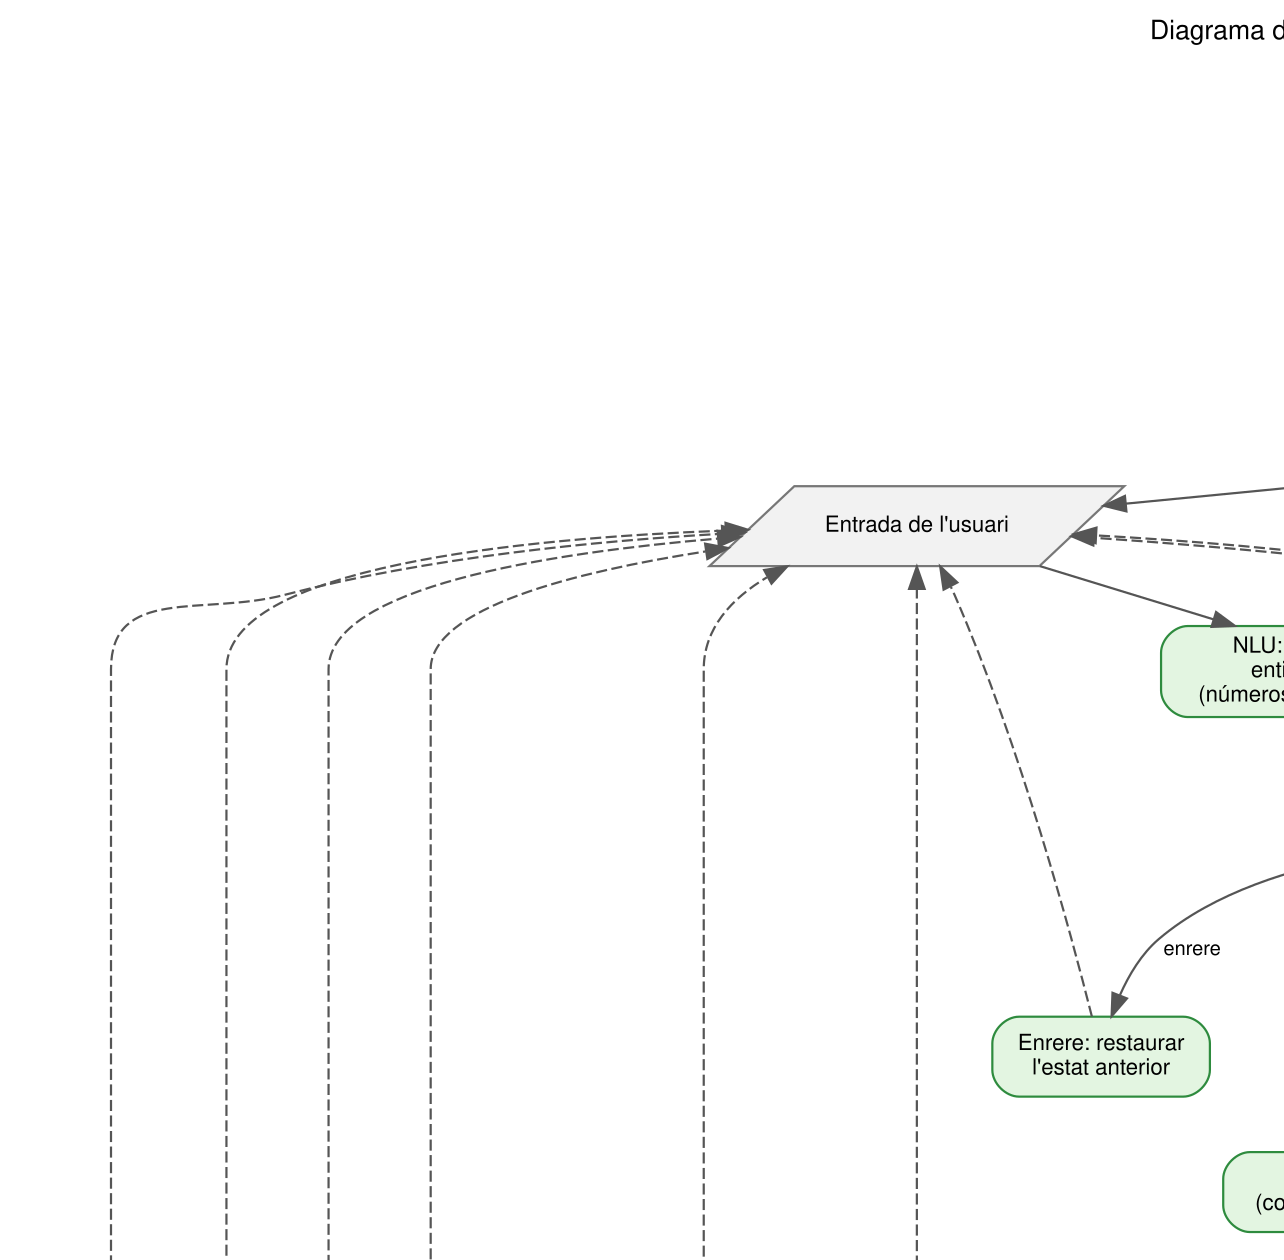

In [18]:
import graphviz

def build_flow_diagram():
    g = graphviz.Digraph('flux_nou_sistema', format='png')
    g.attr(rankdir='TB', fontname='Helvetica', fontsize='12', nodesep='0.3', ranksep='0.35',
           dpi='160', label='Diagrama de flux del sistema de diàleg millorat', labelloc='t')
    g.attr('node', fontname='Helvetica', fontsize='10', shape='box', style='rounded,filled',
           fillcolor='#EAF2FB', color='#2F6DB5')
    g.attr('edge', fontname='Helvetica', fontsize='9', color='#555555')
    D = dict(shape='diamond', style='filled', fillcolor='#FFF4D6', color='#C98A00')
    IO = dict(shape='parallelogram', style='filled', fillcolor='#F2F2F2', color='#777777')
    NEW = dict(fillcolor='#E3F5E1', color='#2E8B3E')          # verd = camí nou respecte l'original

    g.node('start', 'Inici', shape='ellipse', style='filled', fillcolor='#CDEBC6', color='#2E8B3E')
    g.node('welcome', "Benvinguda + instruccions\n('ajuda', 'enrere', 'sortir')", **NEW)
    g.node('ask', 'Preguntar el següent slot pendent\n(adaptada: compra/lloguer;\ningressos només si és lloguer)')
    g.node('in', "Entrada de l'usuari", **IO)
    g.node('nlu', 'NLU: normalitzar, intencions i\nentitats de TOTS els slots\n(números, zones, extres, negacions)', **NEW)
    g.node('glob', 'Intenció\nglobal?', **D)
    g.node('quit', 'Sortir\n(confirmar si és ambigu)', **NEW)
    g.node('help', 'Ajuda contextual', **NEW)
    g.node('back', 'Enrere: restaurar\nl\'estat anterior', **NEW)
    g.node('restart', 'Començar de nou', **NEW)
    g.node('pend', 'Confirmació\npendent?', **D)
    g.node('conf', 'Resoldre sí/no:\npressupost ×1000, canvi a compra,\ningressos anuals → mensuals', **NEW)
    g.node('phase', 'Fase del\ndiàleg', **D)
    g.node('upd', 'Actualitzar el frame\n(iniciativa mixta + correccions)', **NEW)
    g.node('valid', 'Informació\nvàlida?', **D)
    g.node('rep', 'Re-pregunta escalada:\n1) exemple  2) opcions\n3) indiferent', **NEW)
    g.node('sane', 'Valor\nsospitós?', **D)
    g.node('expl', 'Confirmació explícita\n(sí/no)', **NEW)
    g.node('ack', 'Confirmació implícita\nagregada', **NEW)
    g.node('more', 'Queden\nslots?', **D)
    g.node('sum', "Resum + 'És correcte?'", **NEW)
    g.node('sumA', 'Resposta\nal resum', **D)
    g.node('chg', 'Què vols canviar?', **NEW)
    g.node('search', 'Cerca a la BD\n(filtres + regla del 35 %)\n+ rànquing per preu')
    g.node('found', 'Resultats\n> 0?', **D)
    g.node('show', 'Presentar top-3\n(planificació → microplanificació\n→ realització)', **NEW)
    g.node('res', "Acció de\nl'usuari", **D)
    g.node('detail', "Detalls\n('el segon', 'ref. 23')", **NEW)
    g.node('page', "Més resultats ('més')", **NEW)
    g.node('refine', "Afinar la cerca\n('amb terrassa')", **NEW)
    g.node('relax', 'Opcions més properes\n+ oferta de relaxar\nun criteri', **NEW)
    g.node('relA', 'Accepta?', **D)
    g.node('end', 'Comiat', shape='ellipse', style='filled', fillcolor='#F6D0D0', color='#B03030')

    g.edge('start', 'welcome'); g.edge('welcome', 'ask'); g.edge('ask', 'in'); g.edge('in', 'nlu')
    g.edge('nlu', 'glob')
    g.edge('glob', 'quit', 'sortir'); g.edge('quit', 'end')
    g.edge('glob', 'help', 'ajuda'); g.edge('help', 'in', style='dashed')
    g.edge('glob', 'back', 'enrere'); g.edge('back', 'in', style='dashed')
    g.edge('glob', 'restart', 'nova cerca'); g.edge('restart', 'ask', style='dashed')
    g.edge('glob', 'pend', 'no')
    g.edge('pend', 'conf', 'sí'); g.edge('conf', 'more')
    g.edge('pend', 'phase', 'no')
    g.edge('phase', 'upd', 'recollida')
    g.edge('upd', 'valid')
    g.edge('valid', 'rep', 'no'); g.edge('rep', 'in', style='dashed')
    g.edge('valid', 'sane', 'sí')
    g.edge('sane', 'expl', 'sí'); g.edge('expl', 'in', style='dashed')
    g.edge('sane', 'ack', 'no'); g.edge('ack', 'more')
    g.edge('more', 'ask', 'sí')
    g.edge('more', 'sum', 'no'); g.edge('sum', 'in', style='dashed')
    g.edge('phase', 'sumA', 'resum')
    g.edge('sumA', 'search', 'sí'); g.edge('sumA', 'chg', 'no'); g.edge('sumA', 'upd', 'correcció\ndirecta')
    g.edge('chg', 'ask', style='dashed')
    g.edge('search', 'found')
    g.edge('found', 'show', 'sí'); g.edge('found', 'relax', 'no')
    g.edge('show', 'in', style='dashed')
    g.edge('phase', 'res', 'resultats')
    g.edge('res', 'detail'); g.edge('res', 'page'); g.edge('res', 'refine')
    g.edge('res', 'end', "'gràcies' / 'no'")
    g.edge('detail', 'in', style='dashed'); g.edge('page', 'in', style='dashed')
    g.edge('refine', 'search')
    g.edge('relax', 'in', style='dashed')
    g.edge('phase', 'relA', 'relaxació')
    g.edge('relA', 'search', 'sí (relaxar)'); g.edge('relA', 'chg', 'no')
    return g

flow = build_flow_diagram()
flow.render('diagrama_flux_sistema_regles', cleanup=True)   # genera el PNG per a la memòria
flow


## 7.4 Prototip

L'arquitectura segueix l'esquema en cascada de la teoria (sense veu): **NLU → gestor de diàleg → NLG**, amb la base de dades com a *knowledge source*.

### 7.4.1 Model de domini
Normalitzem la base de dades un sol cop (preus a euros, booleans, plantes numèriques) i definim rangs de validació.

In [19]:
# ==========================================================================
# 7.4.1  MODEL DE DOMINI (base de coneixement)
# Normalitzem les dades del JSON un sol cop: preus en euros (int), booleans
# reals, plantes numèriques... Així el gestor de diàleg no ha de tractar
# formats heterogenis com "250k" vs "1200".
# ==========================================================================
import re, math, copy, random, unicodedata, difflib
from collections import Counter

DONTCARE = 'INDIFERENT'          # valor especial: l'usuari no té preferència

def parse_price(value):
    """'250k' -> 250000 ; '1200' -> 1200 ; '1.200 €' -> 1200"""
    s = str(value).strip().lower().replace('€', '').replace(' ', '')
    mult = 1
    if s.endswith('k'):
        mult, s = 1000, s[:-1]
    if re.fullmatch(r'\d{1,3}(\.\d{3})+', s):
        s = s.replace('.', '')
    return int(round(float(s.replace(',', '.')) * mult))

def build_domain(data):
    yes = lambda v: str(v).strip().lower() in ('yes', 'si', 'sí', 'true', '1')
    houses = []
    for h in data['houses']:
        houses.append({
            'id': int(h['id']), 'type': h['type'].strip().lower(),
            'bedrooms': int(h['bedrooms']), 'bathrooms': int(h['bathrooms']),
            'price': parse_price(h['price']), 'square_meters': int(h['square_meters']),
            'floor': int(h.get('floor', 0)), 'elevator': yes(h.get('elevator', 'No')),
            'terrace': yes(h.get('terrace', 'No')),
            'commercial_use': yes(h.get('commercial_use', 'No')),
            'location': h['location'].strip()})
    return houses

# Rangs raonables per validar respostes (no són els de la BD: un usuari pot
# demanar 6 habitacions encara que no n'hi hagi; això ho gestiona la relaxació)
VALID_RANGES = {'bedrooms': (1, 10), 'bathrooms': (1, 6),
                'square_meters': (15, 1000), 'floor': (0, 40)}


### 7.4.2 Lèxic (gramàtica semàntica)
Les regles de comprensió es basen en llistes de paraules i expressions (en català, castellà i anglès), tal com a les *gramàtiques semàntiques* de la teoria: detecció de números, paraules concretes i negacions.

In [20]:
# ==========================================================================
# 7.4.2  LÈXIC (gramàtica semàntica): llistes de paraules en català,
# castellà i anglès. Tot el text es normalitza (minúscules, sense accents)
# abans de comparar, de manera que "Sí", "si" i "SÍ" són equivalents.
# ==========================================================================
INTENT_LEX = {
    'quit':    ['quit', 'exit', 'bye', 'goodbye', 'adeu', 'adeu siau', 'adios', 'sortir',
                'surt', 'salir', 'stop', 'prou'],
    'help':    ['help', 'ajuda', 'ayuda', 'ajudam', 'ajuda m', 'no entenc', 'no entiendo',
                'que puc dir', 'que puedo decir', 'com funciona', 'opcions', 'opciones'],
    'back':    ['enrere', 'endarrere', 'back', 'atras', 'undo', 'desfes', 'desfer',
                'tornar enrere', 'pregunta anterior'],
    'restart': ['comencar de nou', 'tornar a comencar', 'reinicia', 'reiniciar', 'restart',
                'start over', 'empezar de nuevo', 'nova cerca', 'nueva busqueda', 'new search'],
    'dontcare': ['any', 'indiferent', 'igual', 'm es igual', 'es igual', 'tant se val',
                 'tant me fa', 'qualsevol', 'whatever', 'doesn t matter', 'does not matter',
                 'no importa', 'no m importa', 'me da igual', 'da igual', 'cualquiera',
                 'sense preferencia', 'sin preferencia', 'no preference', 'cap preferencia',
                 'prefereixo no dir', 'prefiero no decir', 'no vull dir', 'no ho vull dir',
                 'rather not', 'skip', 'no ho se', 'no lo se', 'ni idea'],
    'affirm':  ['si', 'yes', 'yeah', 'yep', 'clar', 'es clar', 'd acord', 'vale', 'ok',
                'okay', 'correcte', 'correcto', 'exacte', 'exacto', 'perfecte', 'perfecto',
                'sure', 'of course', 'efectivament', 'endavant', 'adelante', 'fet'],
    'negate':  ['no', 'nope', 'no cal', 'cap', 'ninguna', 'ninguno', 'none', 'res', 'gens',
                'tampoc', 'tampoco', 'no gracies', 'no gracias', 'no thanks'],
    'more':    ['mes', 'more', 'mas', 'seguent', 'siguiente', 'next', 'altres', 'otros',
                'others', 'mes opcions'],
    'thanks':  ['gracies', 'gracias', 'thanks', 'thank you', 'merci', 'moltes gracies'],
    'greet':   ['hola', 'hello', 'bon dia', 'bona tarda', 'buenos dias', 'buenas tardes'],
}

NUM_WORDS = {'zero': 0, 'cero': 0, 'u': 1, 'un': 1, 'una': 1, 'uno': 1, 'one': 1,
             'dos': 2, 'dues': 2, 'two': 2, 'tres': 3, 'three': 3, 'quatre': 4,
             'cuatro': 4, 'four': 4, 'cinc': 5, 'cinco': 5, 'five': 5, 'sis': 6,
             'seis': 6, 'six': 6, 'set': 7, 'siete': 7, 'seven': 7, 'vuit': 8,
             'ocho': 8, 'eight': 8, 'nou': 9, 'nueve': 9, 'nine': 9, 'deu': 10,
             'diez': 10, 'ten': 10}
# paraules que poden ser números però sovint no ho són ("un pis", "pis nou")
WEAK_NUM_WORDS = {'u', 'un', 'una', 'uno', 'one', 'set', 'nou', 'deu'}

ORDINALS = {'primer': 1, 'primera': 1, 'primero': 1, 'first': 1,
            'segon': 2, 'segona': 2, 'segundo': 2, 'segunda': 2, 'second': 2,
            'tercer': 3, 'tercera': 3, 'tercero': 3, 'third': 3,
            'quart': 4, 'quarta': 4, 'cuarto': 4, 'cuarta': 4, 'fourth': 4,
            'cinque': 5, 'cinquena': 5, 'quinto': 5, 'quinta': 5, 'fifth': 5,
            'sise': 6, 'sisena': 6, 'sexto': 6, 'sexta': 6, 'sixth': 6,
            'sete': 7, 'setena': 7, 'vuite': 8, 'vuitena': 8, 'nove': 9, 'novena': 9,
            'dese': 10, 'desena': 10}
LAST_WORDS = {'ultim', 'ultima', 'last', 'darrer', 'darrera'}

GROUND_FLOOR = ['planta baixa', 'baixos', 'bajos', 'planta baja', 'ground floor', 'bajo']

UNIT_NOUNS = {   # noms que, al costat d'un número, indiquen a quin slot pertany
    'bedrooms':      {'habitacio', 'habitacions', 'hab', 'habs', 'dormitori', 'dormitoris',
                      'dormitorio', 'dormitorios', 'habitacion', 'habitaciones', 'bedroom',
                      'bedrooms', 'room', 'rooms', 'cambra', 'cambres'},
    'bathrooms':     {'bany', 'banys', 'bano', 'banos', 'lavabo', 'lavabos', 'bathroom',
                      'bathrooms', 'bath', 'baths', 'wc', 'aseo', 'aseos'},
    'square_meters': {'m2', 'm', 'metres', 'metros', 'meters', 'square', 'sqm', 'mts', 'mt'},
    'floor':         {'planta', 'plantes', 'floor'},
    'budget':        {'€', 'eur', 'euro', 'euros', 'pressupost', 'presupuesto', 'budget',
                      'preu', 'precio', 'price', 'pagar', 'pago', 'pay', 'gastar', 'lloguer',
                      'alquiler', 'rent', 'quota'},
    'income':        {'ingressos', 'ingresos', 'income', 'sou', 'sueldo', 'salari',
                      'salario', 'salary', 'nomina', 'guanyo', 'gano', 'cobro', 'cobrem',
                      'guanyem', 'earn', 'ganamos', 'ingresamos', 'cobrar', 'guanyar',
                      'ingressem', 'ingresso', 'ingressa', 'ingressen', 'cobra', 'cobren'},
}
FLOOR_NOUNS = {'planta', 'pis', 'piso', 'floor'}
EURO_WORDS = {'€', 'eur', 'euro', 'euros', 'eurs'}
MILLION_WORDS = {'milio', 'milions', 'millon', 'millones', 'million', 'millions'}
YEAR_WORDS = ['a l any', 'l any', 'anuals', 'anual', 'anuales', 'al ano', 'per year',
              'a year', 'yearly', 'annual', 'bruts', 'brutos']
MONTH_WORDS = ['al mes', 'mensuals', 'mensual', 'mensuales', 'per month', 'a month',
               'monthly', '/ mes', 'cada mes']

QUALIFIERS = [   # (tipus, expressions) — s'avaluen en ordre
    ('gt',  ['mes de', 'mas de', 'more than', 'over', 'superior a']),
    ('lt',  ['menys de', 'menos de', 'less than', 'under', 'inferior a', 'per sota de',
             'por debajo de', 'below']),
    ('max', ['com a maxim', 'maxim', 'maximo', 'como maximo', 'at most', 'max', 'fins a',
             'hasta', 'up to', 'no mes de', 'no mas de', 'nomes', 'solo']),
    ('min', ['almenys', 'com a minim', 'minim', 'minimo', 'al menos', 'como minimo',
             'at least', 'min', 'a partir de', 'a partir del', 'desde', 'from']),
]
RANGE_CONNECTORS = {'a', 'i', 'y', 'and', 'to', 'o', 'or', 'fins'}

LOCATION_ALIASES = {
    'Barcelona': ['barcelona', 'bcn', 'barna', 'ciutat comtal'],
    "L'Hospitalet de Llobregat": ['l hospitalet de llobregat', 'hospitalet de llobregat',
                                  'l hospitalet', 'hospitalet', 'lhospitalet'],
    'Esplugues de Llobregat': ['esplugues de llobregat', 'esplugues'],
    'Santa Coloma de Gramenet': ['santa coloma de gramenet', 'santa coloma', 'sta coloma',
                                 'gramenet', 'coloma'],
}
FUZZY_LOC_KEYS = {'barcelona': 'Barcelona', 'hospitalet': "L'Hospitalet de Llobregat",
                  'esplugues': 'Esplugues de Llobregat', 'gramenet': 'Santa Coloma de Gramenet',
                  'coloma': 'Santa Coloma de Gramenet'}
# Ciutats reals on l'agència no té pisos (per donar una resposta útil)
OTHER_CITIES = ['santa coloma de cervello', 'sant cugat', 'sant boi', 'el prat', 'badalona',
                'sabadell', 'terrassa', 'girona', 'tarragona', 'lleida', 'madrid', 'valencia',
                'mataro', 'cornella', 'castelldefels', 'gava', 'reus', 'sitges',
                'granollers', 'viladecans', 'manresa', 'vic', 'sevilla', 'bilbao']

RENT_PREFIXES, RENT_EXACT = ('llog', 'alquil', 'arrend'), {'rent', 'rental', 'renting', 'rented', 'lease'}
SALE_PREFIXES, SALE_EXACT = ('compr', 'hipotec', 'adquir'), {'venda', 'venta', 'sale', 'buy',
                                                            'buying', 'purchase', 'mortgage'}

FEATURES = ['elevator', 'terrace', 'commercial_use']
FEATURE_WORDS = {
    'elevator':       {'ascensor', 'ascensors', 'elevator', 'lift', 'elevador'},
    'terrace':        {'terrassa', 'terrasses', 'terraza', 'terrazas', 'terrace', 'terraces'},
    'commercial_use': {'comercial', 'comercials', 'commercial', 'negoci', 'negocis', 'negocio',
                       'business', 'local', 'botiga', 'tienda', 'oficina', 'despatx', 'office',
                       'shop'},
}
ALL_WORDS = ['tot', 'totes', 'tots', 'todo', 'todas', 'todos', 'all', 'everything',
             'les tres', 'las tres']
NEG_WORDS = {'no', 'sense', 'sin', 'without', 'ni', 'not', 'cap', 'never', 'nor', 'tampoc',
             'tampoco', 'don', 'doesn', 'didn', 'won'}
POS_MARKERS = {'amb', 'con', 'with', 'si', 'tambe', 'pero', 'but', 'vull', 'quiero'}
EXCLUDE_WORDS = {'menys', 'excepte', 'except', 'excepto', 'salvo', 'no', 'sense', 'sin',
                 'fora', 'not', 'ni'}

SLOT_NAME_WORDS = {   # per detectar de quin criteri parla l'usuari ("canvia la zona")
    'operation':     ['operacio', 'tipus d operacio', 'compra o lloguer'],
    'location':      ['zona', 'ciutat', 'ubicacio', 'lloc', 'barri', 'localitat', 'poblacio',
                      'municipi', 'ciudad', 'location', 'area'],
    'bedrooms':      ['habitacions', 'habitaciones', 'dormitoris', 'bedrooms'],
    'bathrooms':     ['banys', 'banos', 'lavabos', 'bathrooms'],
    'budget':        ['pressupost', 'presupuesto', 'preu', 'precio', 'budget', 'price', 'diners'],
    'income':        ['ingressos', 'ingresos', 'income', 'sou', 'sueldo'],
    'square_meters': ['metres', 'metros', 'superficie', 'mida', 'tamany', 'size', 'm2'],
    'floor':         ['planta', 'altura', 'floor'],
    'extras':        ['extres', 'extras', 'caracteristiques', 'caracteristicas'],
}


### 7.4.3 Comprensió del llenguatge (NLU)
L'NLU retorna **tota** la informació que troba a la frase (no només la que s'ha preguntat). Cada número s'assigna a un slot segons el nom que l'acompanya (`2 habitacions`, `1 bany`, `900 €`, `planta 3`); si no n'hi ha cap, s'assigna a la pregunta actual.

In [21]:
# ==========================================================================
# 7.4.3  COMPRENSIÓ DEL LLENGUATGE (NLU)
# Pas 1: normalització. Pas 2: intencions globals. Pas 3: entitats/slots
# (operació, zona, números amb el seu "context", extres, planta). Retorna
# un diccionari amb TOTA la informació trobada, encara que no sigui la que
# s'ha preguntat (iniciativa mixta).
# ==========================================================================
def strip_accents(text):
    return ''.join(c for c in unicodedata.normalize('NFD', text)
                   if unicodedata.category(c) != 'Mn')

def normalize(text):
    t = text.lower().strip()
    t = t.replace('l·l', 'll').replace('l.l', 'll')
    t = t.replace('m²', 'm2').replace('º', 'o').replace('ª', 'a')
    t = strip_accents(t)
    t = t.replace('€', ' € ').replace('/', ' / ')
    t = re.sub(r"(\d)\s*-\s*(\d)", r"\1 a \2", t)                    # 2-3 -> 2 a 3
    t = re.sub(r"(\d{1,3}) (\d{3})(?= ?(€|eur))", r"\1\2", t)       # 200 000 € -> 200000
    t = re.sub(r"(?<!\d)[.,]|[.,](?!\d)", " ", t)                    # puntuació fora de números
    t = re.sub(r"[^a-z0-9€.,/%\s]", " ", t)                          # apòstrofs, ?, !, #...
    t = re.sub(r"(\d)(k|m2|m|mil|eur|euros|hab|habs|mes)\b", r"\1 \2", t)   # 35k -> 35 k
    t = re.sub(r"(\d)%", r"\1 %", t)
    return re.sub(r"\s+", " ", t).strip()

def has_phrase(norm, phrases):
    return any(re.search(r'(?<![a-z0-9])' + re.escape(p) + r'(?![a-z0-9])', norm)
               for p in phrases)

def phrase_positions(toks, phrase):
    p = phrase.split()
    return [i for i in range(len(toks) - len(p) + 1) if toks[i:i + len(p)] == p]

def is_numberish(tok):
    return bool(re.fullmatch(r'\d+(?:[.,]\d+)*', tok)) or tok in NUM_WORDS

def parse_number_token(tok):
    if re.fullmatch(r'\d{1,3}(?:\.\d{3})+', tok):     # 1.200 / 200.000 (separador de milers)
        return float(tok.replace('.', ''))
    if re.fullmatch(r'\d{1,3}(?:,\d{3})+', tok):      # 200,000 (format anglès)
        return float(tok.replace(',', ''))
    return float(tok.replace(',', '.'))              # 1,5 / 2.5 (decimals)


class NLU:
    NUMERIC_SLOTS = {'bedrooms', 'bathrooms', 'budget', 'income', 'square_meters', 'floor'}

    def __init__(self, locations):
        self.locations = locations

    # ---------------- punt d'entrada ----------------
    def parse(self, text, expected=None):
        norm = normalize(text)
        toks = norm.split()
        r = {'text': text, 'norm': norm, 'toks': toks, 'intents': set(), 'slots': {},
             'unavailable': [], 'ambiguous_numbers': [], 'refs': [], 'slot_names': set(),
             'invalid': []}
        if not toks:
            r['intents'].add('help' if text.strip() == '?' else 'empty')
            return r
        self._intents(r)
        for slot, words in SLOT_NAME_WORDS.items():
            if has_phrase(norm, words):
                r['slot_names'].add(slot)
        self._operation(r)
        self._locations(r, expected)
        self._numbers(r, expected)
        self._ground_floor(r)
        self._extras(r, expected)
        self._refs(r)
        return r

    # ---------------- intencions ----------------
    def _intents(self, r):
        norm, I = r['norm'], r['intents']
        for intent, phrases in INTENT_LEX.items():
            if has_phrase(norm, phrases):
                I.add(intent)
        if norm in ('y', 's'):
            I.add('affirm')
        if norm == 'n':
            I.add('negate')
        if r['text'].strip() == '?':
            I.add('help')
        if 'dontcare' in I:                     # "no m'importa" no és una negació
            I.discard('negate')
        if 'affirm' in I and 'negate' in I:     # "no, no és correcte" / "sí, però..."
            I.discard('affirm' if r['toks'][0] in ('no', 'nope', 'n') else 'negate')

    # ---------------- operació (compra / lloguer) ----------------
    def _operation(self, r):
        toks = r['toks']
        found = {}
        for i, t in enumerate(toks):
            op = None
            if t in RENT_EXACT or (t.startswith(RENT_PREFIXES)):
                op = 'rent'
            elif t in SALE_EXACT or t.startswith(SALE_PREFIXES):
                op = 'sale'
            if op:
                found[op] = found.get(op, False) or not self._negated(toks, i)
        positives = [op for op, pos in found.items() if pos]
        if len(positives) == 1:
            r['slots']['operation'] = positives[0]
        elif not positives and len(found) == 1:     # "no vull comprar" -> lloguer
            r['slots']['operation'] = 'rent' if 'sale' in found else 'sale'

    # ---------------- zona ----------------
    def _terrassa_is_city(self, toks, i, text):
        prev = toks[i - 1] if i > 0 else ''
        prev2 = toks[i - 2] if i > 1 else ''
        if prev in ('amb', 'con', 'with', 'una', 'un', 'la', 'sense', 'sin', 'without', 'ni'):
            return False
        if prev in ('a', 'en', 'in', 'de', 'at') and prev2 not in ('amb', 'con', 'with'):
            return True
        return bool(re.search(r'(?<!^)(?<![.!?]\s)\bTerrassa\b', text.strip()))

    def _locations(self, r, expected):
        norm, toks, text = r['norm'], r['toks'], r['text']
        work = norm
        for city in sorted(OTHER_CITIES, key=len, reverse=True):
            if has_phrase(work, [city]):
                if city == 'terrassa':
                    idx = [i for i, t in enumerate(toks) if t == 'terrassa']
                    if not any(self._terrassa_is_city(toks, i, text) for i in idx):
                        continue
                r['unavailable'].append(city)
                work = re.sub(r'(?<![a-z0-9])' + re.escape(city) + r'(?![a-z0-9])', ' ', work)
        wtoks = work.split()
        found, excluded = set(), set()
        for loc, aliases in LOCATION_ALIASES.items():
            for alias in sorted(aliases, key=len, reverse=True):
                pos = phrase_positions(wtoks, alias)
                if pos:
                    p = pos[0]
                    window = wtoks[max(0, p - 3):p]
                    (excluded if any(w in EXCLUDE_WORDS for w in window) else found).add(loc)
                    break
        if 'llobregat' in wtoks and not ({'Esplugues de Llobregat', "L'Hospitalet de Llobregat"} & (found | excluded)):
            found |= {'Esplugues de Llobregat', "L'Hospitalet de Llobregat"}
        if not found and not excluded:                      # errors tipogràfics
            capitalized = {normalize(w) for w in re.findall(r"\b[A-ZÀ-Ý][\w'·]+", text)}
            for t in wtoks:
                if len(t) >= 5 and (expected == 'location' or t in capitalized):
                    m = difflib.get_close_matches(t, FUZZY_LOC_KEYS.keys(), n=1, cutoff=0.8)
                    if m:
                        found.add(FUZZY_LOC_KEYS[m[0]])
        if found:
            r['slots']['location'] = sorted(found)
        elif excluded:
            r['slots']['location'] = sorted(set(self.locations) - excluded)

    # ---------------- números ----------------
    def _numbers(self, r, expected):
        toks = r['toks']
        ments = []
        for i, tok in enumerate(toks):
            val, kind = None, 'card'
            if re.fullmatch(r'\d+(?:[.,]\d+)*', tok):
                val = parse_number_token(tok)
            elif tok in ORDINALS:
                val, kind = ORDINALS[tok], 'ord'
            elif re.fullmatch(r'(\d+)(r|n|t|a|e|o|er|ra|na|ta|st|nd|rd|th)', tok):
                val, kind = int(re.match(r'\d+', tok).group()), 'ord'
            elif tok in NUM_WORDS:
                val = NUM_WORDS[tok]
            elif tok == 'mil' and (i == 0 or not is_numberish(toks[i - 1])):
                val = 1000
            if val is None:
                continue
            m = {'value': val, 'pos': i, 'end': i, 'kind': kind, 'raw': tok,
                 'weak': tok in WEAK_NUM_WORDS, 'money': False, 'period': None, 'qual': None,
                 'percent': i + 1 < len(toks) and toks[i + 1] == '%'}
            nxt = toks[i + 1] if i + 1 < len(toks) else ''
            if nxt in ('k', 'mil'):
                m['value'] *= 1000; m['money'] = True; m['end'] = i + 1
            elif nxt in MILLION_WORDS:
                m['value'] *= 1_000_000; m['money'] = True; m['end'] = i + 1
            after = toks[m['end'] + 1:m['end'] + 3]
            if any(w in EURO_WORDS for w in after) or (i > 0 and toks[i - 1] in EURO_WORDS):
                m['money'] = True
            ctx = ' '.join(toks[m['end'] + 1:m['end'] + 6])
            if has_phrase(ctx, YEAR_WORDS):
                m['period'] = 'year'
            elif has_phrase(ctx, MONTH_WORDS):
                m['period'] = 'month'
            before = ' '.join(toks[max(0, i - 4):i])
            for q, phrases in QUALIFIERS:
                if has_phrase(before, phrases):
                    m['qual'] = q
                    break
            ments.append(m)
        ments = [m for m in ments if not m['percent']]
        # rangs: "2 o 3", "entre 700 i 900", "2-3"
        for a, b in zip(ments, ments[1:]):
            if b['pos'] - a['end'] == 2 and toks[a['end'] + 1] in RANGE_CONNECTORS \
                    and a['kind'] == b['kind'] == 'card':
                a['range'] = b
                b['partner'] = a
                a['money'] = b['money'] = a['money'] or b['money']

        slots, unattached = {}, []
        for m in ments:
            if 'partner' in m:
                continue
            slot = self._attach(m, toks, expected)
            if 'range' in m:
                if slot is None:
                    slot = self._attach(m['range'], toks, expected)
                lo, hi = sorted([m['value'], m['range']['value']])
                m = dict(m, value=hi if slot in ('budget',) else lo, weak=False)
            if m['weak'] and slot is None and len(toks) > 1:
                continue
            if slot is None:
                unattached.append(m)
            elif slot not in slots:
                slots[slot] = m
        if unattached and expected in self.NUMERIC_SLOTS and expected not in slots:
            strong = [m for m in unattached if not m['weak']] or unattached
            if len(strong) == 1:
                slots[expected] = strong[0]
            else:
                r['ambiguous_numbers'] = [m['value'] for m in strong]
        for slot, m in slots.items():
            self._to_slot_value(r, slot, m, expected)

    def _attach(self, m, toks, expected):
        after = toks[m['end'] + 1:m['end'] + 4]
        before = toks[max(0, m['pos'] - 2):m['pos']]
        if m['kind'] == 'ord':
            if (after and after[0] in FLOOR_NOUNS) or (before and before[-1] in FLOOR_NOUNS) \
                    or expected == 'floor':
                return 'floor'
            return None                          # "el segon" -> expressió referencial
        for w in after:                          # el nom més proper DESPRÉS del número
            if is_numberish(w):
                break
            if w == 'm' and expected == 'budget' and m['value'] < 10:
                m['value'] *= 1_000_000
                return 'budget'
            for slot in ('bedrooms', 'bathrooms', 'square_meters', 'floor'):
                if w in UNIT_NOUNS[slot]:
                    return slot
        near = toks[max(0, m['pos'] - 4):m['end'] + 4]
        if any(w in UNIT_NOUNS['income'] for w in near):
            return 'income'
        if m['money']:
            return 'budget'
        for w in reversed(before):               # "planta 3", "habitacions: 2", "pagar 700"
            for slot in ('floor', 'bedrooms', 'bathrooms', 'budget', 'square_meters'):
                if w in UNIT_NOUNS[slot]:
                    return slot
        return None

    def _to_slot_value(self, r, slot, m, expected):
        v, q = m['value'], m['qual']
        if slot in ('bedrooms', 'bathrooms', 'square_meters'):
            v = int(v) + (1 if q == 'gt' else 0)
            lo, hi = VALID_RANGES[slot]
            if not lo <= v <= hi:
                r['invalid'].append((slot, v)); return
            r['slots'][slot] = v
        elif slot == 'floor':
            v = int(v)
            if not 0 <= v <= VALID_RANGES['floor'][1]:
                r['invalid'].append((slot, v)); return
            r['slots']['floor'] = {'max': v} if q in ('max', 'lt') else {'min': v + (1 if q == 'gt' else 0)}
        elif slot == 'budget':
            if v <= 0:
                r['invalid'].append((slot, v)); return
            r['slots']['budget'] = int(round(v))
            r['budget_money'] = m['money']
        elif slot == 'income':
            if v <= 0:
                r['invalid'].append((slot, v)); return
            r['slots']['income'] = int(round(v))
            r['income_period'] = m['period']

    def _ground_floor(self, r):
        norm, toks = r['norm'], r['toks']
        for g in GROUND_FLOOR:
            pos = phrase_positions(toks, g)
            if pos:
                p = pos[0]
                window = toks[max(0, p - 4):p]
                before = ' '.join(window)
                if any(w in NEG_WORDS for w in window):
                    r['slots']['floor'] = {'min': 1}          # "que no sigui planta baixa"
                elif has_phrase(before, ['nomes', 'solo', 'only', 'com a maxim', 'maxim', 'maximo']):
                    r['slots']['floor'] = {'max': 0}
                else:
                    r['slots']['floor'] = {'min': 0}
                return

    # ---------------- extres (ascensor, terrassa, ús comercial) ----------------
    def _negated(self, toks, i):
        window = toks[max(0, i - 4):i]
        last_neg = max([k for k, w in enumerate(window) if w in NEG_WORDS], default=None)
        if last_neg is None:
            return False
        return not any(w in POS_MARKERS for w in window[last_neg + 1:])

    def _extras(self, r, expected):
        toks, norm = r['toks'], r['norm']
        res = {}
        for feat, words in FEATURE_WORDS.items():
            for i, t in enumerate(toks):
                if t in words:
                    if feat == 'terrace' and 'terrassa' in r['unavailable']:
                        continue
                    res[feat] = not self._negated(toks, i)
        if expected == 'extras' and has_phrase(norm, ALL_WORDS) and not res:
            res = {f: True for f in FEATURES}
        if res:
            r['slots']['extras'] = res

    # ---------------- expressions referencials ("el segon", "ref. 23") ----------------
    def _refs(self, r):
        toks = r['toks']
        for i, t in enumerate(toks):
            nxt = toks[i + 1] if i + 1 < len(toks) else ''
            if nxt in FLOOR_NOUNS:
                continue
            if t in ORDINALS:
                r['refs'].append(('index', ORDINALS[t] - 1))
            elif re.fullmatch(r'\d(r|n|a|o|st|nd|rd)', t) and i > 0 and toks[i - 1] in ('el', 'la', 'the'):
                r['refs'].append(('index', int(t[0]) - 1))
            elif t in LAST_WORDS:
                r['refs'].append(('index', -1))
        for m in re.finditer(r'\b(?:ref|referencia|id|numero|num|pis|casa|habitatge|el|la)\s+(\d{1,3})\b(?!\s*(?:habitacio|bany|m2|m\b|metres|€|euros|k\b|planta))', r['norm']):
            r['refs'].append(('id', int(m.group(1))))


### 7.4.4 Generació del llenguatge (NLG): microplanificació i realització

| Fase | Sistema original | Sistema millorat |
|---|---|---|
| **Planificació** | es mostren totes les cases en l'ordre del JSON | selecció del top-3 ordenat per preu, amb paginació; si no hi ha resultats, se seleccionen les opcions *més properes* (menys criteris incomplerts) |
| **Microplanificació: confirmació** | cap | confirmació implícita **agregada** dels slots entesos en un torn ("Molt bé: un habitatge de lloguer a Barcelona, almenys 2 habitacions i un màxim de 900 €/mes.") |
| **Microplanificació: marcadors discursius** | cap | "D'acord", "Entesos", "Perfecte"… amb variació; "**I** quants banys?" |
| **Microplanificació: expressions referencials** | "House ID: 3" | "El primer, el més econòmic, …", "El segon…", "el pis de ref. 23"; també es poden fer servir per demanar detalls |
| **Microplanificació: contingut rellevant** | tots els camps | èmfasi en el que s'ha demanat ("Té la terrassa que buscaves"), extres no demanats ("A més, admet ús comercial"), avisos ("a la 3a planta sense ascensor"), relació amb el pressupost i els ingressos ("el 32 % dels teus ingressos") |
| **Microplanificació: explicacions** | "Sorry, no suitable houses" | "… compleix la resta de criteris, però costa 360.000 € (160.000 € més del teu pressupost)" |
| **Realització: números** | `250k euros`, `1200 euros`, `100 m^2` | `250.000 €`, `1.200 €/mes`, `100 m²` |
| **Realització: concordança** | `Bedrooms: 1` | "1 habitació", "2 habitacions", "1 bany" |
| **Realització: ordinals** | `Floor: 0` | "planta baixa", "3a planta" |
| **Realització: morfologia** | — | elisió ("d'habitacions"), article ("a l'Hospitalet"), enumeracions amb comes i "i"/"o"/"ni" |

In [22]:
# ==========================================================================
# 7.4.4  GENERACIÓ DEL LLENGUATGE (NLG)
#  - Realització: formatació de números i preus, concordança singular/plural,
#    ordinals, elisió de "de" (d'habitacions), article davant de l'Hospitalet,
#    enumeracions amb comes i "i"/"o".
#  - Microplanificació: fragments per slot que s'agreguen en una sola frase
#    (confirmació implícita), marcadors discursius variats, expressions
#    referencials ("el primer", "el més econòmic"), èmfasi en el que l'usuari
#    ha demanat, avisos (planta alta sense ascensor), comparacions amb el
#    pressupost i els ingressos.
# ==========================================================================
def fmt_num(n):
    return f"{int(round(n)):,}".replace(',', '.')

def fmt_eur(n, monthly=False):
    return fmt_num(n) + ' €' + ('/mes' if monthly else '')

def plural(n, sing, plur):
    return f"{n} {sing if n == 1 else plur}"

def join_list(items, conj='i'):
    items = [x for x in items if x]
    if not items:
        return ''
    if len(items) == 1:
        return items[0]
    return ', '.join(items[:-1]) + f' {conj} ' + items[-1]

def de(word):
    """Elisió: de + habitacions -> d'habitacions"""
    return ("d'" if strip_accents(word[0].lower()) in 'aeiouh' else 'de ') + word

def loc_s(loc):
    """Nom del municipi dins d'una frase: L'Hospitalet -> l'Hospitalet"""
    return loc[0].lower() + loc[1:] if loc.startswith("L'") else loc

def floor_name(n):
    return 'planta baixa' if n == 0 else f'{n}a planta'

def cap(s):
    return s[:1].upper() + s[1:]

SLOT_LABEL = {'operation': 'operació', 'location': 'zona', 'bedrooms': 'habitacions',
              'bathrooms': 'banys', 'budget': 'pressupost', 'income': 'ingressos',
              'square_meters': 'superfície', 'floor': 'planta', 'extras': 'extres'}
SLOT_ART = {'operation': "l'operació", 'location': 'la zona', 'bedrooms': 'les habitacions',
            'bathrooms': 'els banys', 'budget': 'el pressupost', 'income': 'els ingressos',
            'square_meters': 'la superfície', 'floor': 'la planta', 'extras': 'els extres'}
FEAT_LABEL = {'elevator': 'ascensor', 'terrace': 'terrassa', 'commercial_use': 'ús comercial'}
FEAT_ART = {'elevator': "l'ascensor", 'terrace': 'la terrassa', 'commercial_use': "l'ús comercial"}
ACK_MARKERS = ["D'acord", 'Perfecte', 'Entesos', 'Molt bé', 'Genial']
ORD_REF = ['El primer', 'El segon', 'El tercer', 'El quart', 'El cinquè', 'El sisè',
           'El setè', 'El vuitè', 'El novè', 'El desè']
EXAMPLES = {'operation': "'vull llogar' o 'per comprar'",
            'location': "'Barcelona' o 'a Esplugues'",
            'bedrooms': "'2' o 'dues habitacions'",
            'bathrooms': "'1' o 'un bany'",
            'budget': "'900 €' per a un lloguer o '250.000 €' per a una compra",
            'income': "'2.000 € al mes'",
            'square_meters': "'70 m2'",
            'floor': "'planta baixa', 'a partir de la 2a' o 'com a màxim la 1a'",
            'extras': "'amb ascensor i terrassa' o 'cap'"}
WELCOME = ("Hola! Sóc l'assistent de cerca d'habitatges. T'ajudaré a trobar un pis que "
           "s'adapti al que necessites. Pots respondre amb frases normals (per exemple: "
           "'vull llogar un pis de 2 habitacions a Barcelona'). En qualsevol moment pots dir "
           "'ajuda', 'enrere', 'començar de nou' o 'sortir'.")
FAREWELL = "Gràcies per fer servir l'assistent d'habitatges. Fins aviat!"


class NLG:
    def __init__(self, bot):
        self.bot = bot
        self.last_marker = None

    def marker(self):
        options = [m for m in ACK_MARKERS if m != self.last_marker]
        self.last_marker = self.bot.rng.choice(options)
        return self.last_marker

    # ---------- fragments de microplanificació (un per slot) ----------
    def fragment(self, slot, value):
        rent = self.bot.frame['operation'] == 'rent'
        if value == DONTCARE:
            return 'sense indicar ingressos' if slot == 'income' else f"sense preferència {de(SLOT_LABEL[slot])}"
        if slot == 'operation':
            return 'un habitatge de lloguer' if value == 'rent' else 'un habitatge per comprar'
        if slot == 'location':
            return 'a ' + join_list([loc_s(l) for l in value], 'o')
        if slot == 'bedrooms':
            return 'almenys ' + plural(value, 'habitació', 'habitacions')
        if slot == 'bathrooms':
            return 'almenys ' + plural(value, 'bany', 'banys')
        if slot == 'budget':
            return 'un màxim de ' + fmt_eur(value, monthly=rent)
        if slot == 'income':
            return 'uns ingressos de ' + fmt_eur(value, monthly=True)
        if slot == 'square_meters':
            return f'almenys {value} m²'
        if slot == 'floor':
            return self.floor_fragment(value)
        if slot == 'extras':
            wanted = [FEAT_LABEL[f] for f in FEATURES if value.get(f)]
            return ('amb ' + join_list(wanted)) if wanted else "sense requisits d'ascensor, terrassa ni ús comercial"

    def floor_fragment(self, v):
        if 'max' in v:
            return 'a la planta baixa' if v['max'] == 0 else f"com a màxim a la {floor_name(v['max'])}"
        return 'a qualsevol planta' if v['min'] == 0 else f"a partir de la {floor_name(v['min'])}"

    def ack(self, updated, corrected):
        msgs = []
        if corrected:
            frags = [self.fragment(s, self.bot.frame[s]) for s in corrected]
            labels = join_list([SLOT_ART[s] for s in corrected])
            verb = 'actualitzo' if corrected == ['extras'] else 'corregeixo'
            msgs.append(f"Entesos, {verb} {labels}: ara {join_list(frags)}.")
        new = [s for s in updated if s not in corrected]
        if new:
            frags = [self.fragment(s, self.bot.frame[s]) for s in new]
            if 'operation' in new and 'location' in new and self.bot.frame['location'] != DONTCARE:
                i, j = new.index('operation'), new.index('location')   # agregació: "per comprar a Barcelona"
                frags[i] = frags[i] + ' ' + frags[j]
                frags.pop(j); new = [x for x in new if x != 'location']
            if 'bedrooms' in new and 'bathrooms' in new and DONTCARE not in (self.bot.frame['bedrooms'], self.bot.frame['bathrooms']):
                i, j = new.index('bedrooms'), new.index('bathrooms')   # "almenys 3 habitacions i 2 banys"
                frags[i] = frags[i] + ' i ' + plural(self.bot.frame['bathrooms'], 'bany', 'banys')
                frags.pop(j)
            msgs.append(f"{self.marker()}: {join_list(frags)}.")
        return ' '.join(msgs)

    # ---------- preguntes (adaptades al context) ----------
    def question(self, slot):
        b = self.bot
        op = b.frame['operation']
        if slot == 'operation':
            return 'Per començar, busques un habitatge per comprar o per llogar?'
        if slot == 'location':
            counts = Counter(h['location'] for h in b.houses if op is None or h['type'] == op)
            opts = join_list([f"{loc_s(l)} ({n})" for l, n in sorted(counts.items())])
            kind = {'rent': 'de lloguer ', 'sale': 'en venda '}.get(op, '')
            return f"A quina zona t'agradaria viure? Tenim habitatges {kind}a {opts}."
        if slot == 'bedrooms':
            return 'Quantes habitacions necessites, com a mínim?'
        if slot == 'bathrooms':
            return 'I quants banys, com a mínim?'
        if slot == 'budget':
            if op == 'rent':
                return 'Quin és el lloguer màxim que vols pagar al mes?'
            return 'Quin és el teu pressupost màxim per a la compra?'
        if slot == 'income':
            return ("Per no recomanar-te lloguers que superin el 35 % dels ingressos, quins són "
                    "els ingressos mensuals nets de la llar? (Si prefereixes no dir-ho, respon "
                    "'prefereixo no dir-ho'.)")
        if slot == 'square_meters':
            return 'Quants metres quadrats necessites, com a mínim?'
        if slot == 'floor':
            return ("A partir de quina planta t'agradaria viure? (p. ex. 'planta baixa', "
                    "'a partir de la 2a' o 'com a màxim la 1a')")
        if slot == 'extras':
            known = [f for f in FEATURES if b.frame['extras'].get(f)]
            rest = [FEAT_LABEL[f] for f in FEATURES if f not in b.frame['extras']]
            if known and rest:
                return (f"A més de {join_list([FEAT_LABEL[f] for f in known])}, necessites "
                        f"{join_list(rest, 'o')}?")
            return ("Necessites que tingui ascensor, terrassa o que admeti ús comercial? "
                    "Pots dir-ne diversos, o 'cap'.")

    def invalid(self, slot, v):
        if slot not in VALID_RANGES:
            return f"{cap(SLOT_ART[slot])} ha de ser una quantitat positiva."
        lo, hi = VALID_RANGES[slot]
        what = {'bedrooms': lambda x: plural(x, 'habitació', 'habitacions'),
                'bathrooms': lambda x: plural(x, 'bany', 'banys'),
                'square_meters': lambda x: f'{x} m²',
                'floor': lambda x: f'la planta {x}'}[slot]
        return f"Hmm, {what(v)}? No sembla un valor realista: indica'n entre {lo} i {hi}."

    def options_text(self, slot):
        if slot == 'location':
            opts = ' '.join(f"{i}) {l}" for i, l in enumerate(self.bot.locations, 1))
            return f"Escriu el nom o el número de la zona: {opts}. També pots dir 'indiferent'."
        if slot == 'operation':
            return "Escriu només 'comprar' o 'llogar'."
        if slot == 'extras':
            return "Digues les característiques que vulguis ('ascensor', 'terrassa', 'ús comercial') o 'cap'."
        if slot in VALID_RANGES:
            lo, hi = VALID_RANGES[slot]
            return f"Escriu només un número (entre {lo} i {hi}) o 'indiferent'."
        return f"Escriu només la quantitat en euros (p. ex. {EXAMPLES[slot]}) o 'indiferent'."

    # ---------- resum abans de cercar (agregació) ----------
    def summary(self):
        f = self.bot.frame
        head = self.fragment('operation', f['operation'])
        loc = f['location']
        parts = [head + (' ' + self.fragment('location', loc) if loc not in (None, DONTCARE) else ' a qualsevol zona')]
        rooms = []                                  # agregació: "amb almenys 2 habitacions i 1 bany"
        if isinstance(f['bedrooms'], int):
            rooms.append(plural(f['bedrooms'], 'habitació', 'habitacions'))
        if isinstance(f['bathrooms'], int):
            rooms.append(plural(f['bathrooms'], 'bany', 'banys'))
        if rooms:
            parts.append('amb almenys ' + join_list(rooms))
        if isinstance(f['square_meters'], int):
            parts.append(f"d'almenys {f['square_meters']} m²")
        if isinstance(f['floor'], dict):
            parts.append(self.floor_fragment(f['floor']))
        feats = [FEAT_LABEL[x] for x in FEATURES if f['extras'].get(x)]
        if feats:
            parts.append('amb ' + join_list(feats))
        s1 = 'Resumint, busques ' + join_list(parts) + '.'
        s2 = ''
        if isinstance(f['budget'], int):
            s2 = f"El pressupost màxim és de {fmt_eur(f['budget'], f['operation'] == 'rent')}"
            if isinstance(f['income'], int):
                s2 += f" i els ingressos de la llar, de {fmt_eur(f['income'], True)}"
            s2 += '.'
        dc = [SLOT_LABEL[s] for s in ('location', 'bedrooms', 'bathrooms', 'budget',
                                      'square_meters', 'floor') if f[s] == DONTCARE and s != 'location']
        s3 = ('No tens preferència ' + join_list([de(x) for x in dc], 'ni') + '.') if dc else ''
        return ' '.join(x for x in (s1, s2, s3, 'És correcte?') if x)

    # ---------- presentació de resultats ----------
    def house_line(self, h, i, n, largest_id, first_page, gi):
        b, f = self.bot, self.bot.frame
        rent = h['type'] == 'rent'
        tags = []
        if n > 1 and i == 0 and first_page:
            tags.append('el més econòmic')
        if n > 1 and h['id'] == largest_id:
            tags.append('el més espaiós')
        op_w = 'de lloguer' if rent else 'en venda'
        where = f"a {loc_s(h['location'])} (ref. {h['id']})"
        body = (f"{plural(h['bedrooms'], 'habitació', 'habitacions')} i "
                f"{plural(h['bathrooms'], 'bany', 'banys')}, {h['square_meters']} m², "
                f"{self.floor_phrase(h)}")
        if n > 1:
            subj = ORD_REF[gi] if gi < len(ORD_REF) else f"El número {gi + 1}"
            if tags:
                subj += ', ' + join_list(tags) + ','
            s1 = f"{subj} és un pis {op_w} {where}: {body}."
        else:
            s1 = f"És un pis {op_w} {where}: {body}."
        s2 = f"Costa {fmt_eur(h['price'])}" + (' al mes' if rent else '')
        extra = []
        if rent and isinstance(f['income'], int):
            extra.append(f"el {round(100 * h['price'] / f['income'])} % dels teus ingressos")
        if isinstance(f['budget'], int) and f['budget'] - h['price'] >= 0.05 * f['budget']:
            extra.append(f"{fmt_eur(f['budget'] - h['price'])} per sota del teu pressupost")
        s2 += (' (' + '; '.join(extra) + ')' if extra else '') + '.'
        return ' '.join(x for x in (s1, s2, self.feature_sentence(h)) if x)

    def floor_phrase(self, h):
        s = 'a la ' + floor_name(h['floor'])
        if h['elevator']:
            s += ' amb ascensor'
        elif h['floor'] >= 3:
            s += ' sense ascensor'            # avís útil (microplanificació)
        return s

    def feature_sentence(self, h):
        wanted = self.bot.frame['extras']
        verb = {'terrace': 'té terrassa', 'commercial_use': 'admet ús comercial'}
        req = [f for f in ('terrace', 'commercial_use') if wanted.get(f) and h[f]]
        bonus = [f for f in ('terrace', 'commercial_use') if h[f] and not wanted.get(f)]
        out = []
        if req:
            txt = join_list([{'terrace': 'té la terrassa que buscaves',
                              'commercial_use': 'admet ús comercial, com volies'}[f] for f in req])
            out.append(cap(txt) + '.')
        if bonus:
            out.append('A més, ' + join_list([verb[f] for f in bonus]) + '.')
        return ' '.join(out)

    def results(self, page, total, first, remaining, first_page, start=0):
        n = len(page)
        if first:
            if total == 1:
                head = 'Només he trobat un habitatge que encaixi amb el que busques:'
            elif total <= n:
                head = f"He trobat {total} habitatges que encaixen amb el que busques, del més econòmic al més car:"
            else:
                head = (f"He trobat {total} habitatges que encaixen amb el que busques. "
                        f"T'ensenyo els {n} més econòmics:")
        else:
            head = f"Aquí en tens {n} més:"
        allr = self.bot.results                # comparacions sobre TOTS els resultats, no la pàgina
        top = max(h['square_meters'] for h in allr)
        largest = next(h['id'] for h in allr if h['square_meters'] == top) if total > 1 else None
        if sum(h['square_meters'] == top for h in allr) > 1:
            largest = None                     # empat: no té sentit dir "el més espaiós"
        lines = [head] + ['  • ' + self.house_line(h, i, n if first_page else 2, largest, first_page, start + i)
                          for i, h in enumerate(page)]
        lines.append(self.results_prompt(remaining))
        return '\n'.join(lines)

    def results_prompt(self, remaining):
        opts = []
        if remaining > 0:
            opts.append(f"'més' per veure'n {min(remaining, self.bot.max_show)} més")
        opts += ["'el primer' (o la referència) per veure'n els detalls",
                 "afinar la cerca (p. ex. 'amb terrassa' o 'fins a 800 €')",
                 "'nova cerca'", "'sortir'"]
        return 'Pots dir ' + join_list(opts, 'o') + '.'

    def detail(self, h, violations):
        rent = h['type'] == 'rent'
        yes = [FEAT_LABEL[f] for f in FEATURES if h[f] and f != 'commercial_use']
        no = [FEAT_LABEL[f] for f in FEATURES if not h[f] and f != 'commercial_use']
        s = (f"Detalls del pis de ref. {h['id']}: {'lloguer' if rent else 'venda'} a "
             f"{loc_s(h['location'])}, {fmt_eur(h['price'], rent)}, "
             f"{plural(h['bedrooms'], 'habitació', 'habitacions')} i "
             f"{plural(h['bathrooms'], 'bany', 'banys')}, {h['square_meters']} m², "
             f"a la {floor_name(h['floor'])}. ")
        feats = []
        if yes:
            feats.append('Té ' + join_list(yes))
        if no:
            feats.append(('però no té ' if yes else 'No té ') + join_list(no, 'ni'))
        s += cap(', '.join(feats)) + ', i ' + ('admet' if h['commercial_use'] else 'no admet') + ' ús comercial. '
        if violations:
            s += 'Respecte al que busques, ' + join_list([self.violation(h, v) for v in violations]) + '.'
        else:
            s += 'Compleix tots els teus criteris.'
        return s

    # ---------- relaxació (cap resultat) ----------
    def violation(self, h, v):
        slot, feat = v
        f = self.bot.frame
        rent = h['type'] == 'rent'
        if slot == 'location':
            return f"és a {loc_s(h['location'])}"
        if slot == 'bedrooms':
            return f"només té {plural(h['bedrooms'], 'habitació', 'habitacions')}"
        if slot == 'bathrooms':
            return f"només té {plural(h['bathrooms'], 'bany', 'banys')}"
        if slot == 'square_meters':
            return f"fa {h['square_meters']} m²"
        if slot == 'budget':
            return (f"costa {fmt_eur(h['price'], rent)} ({fmt_eur(h['price'] - f['budget'])} "
                    f"més del teu pressupost)")
        if slot == 'income':
            return (f"el lloguer representa el {round(100 * h['price'] / f['income'])} % dels "
                    f"teus ingressos (més del 35 %)")
        if slot == 'floor':
            return f"és a la {floor_name(h['floor'])}"
        if slot == 'extras':
            return {'elevator': 'no té ascensor', 'terrace': 'no té terrassa',
                    'commercial_use': 'no admet ús comercial'}[feat]

    def near_line(self, h, viols):
        where = '' if any(s == 'location' for s, _ in viols) else f", a {loc_s(h['location'])},"
        return (f"El pis de ref. {h['id']}{where} compleix la resta de criteris, però "
                f"{join_list([self.violation(h, v) for v in viols])}.")

    def relax_offer(self, slot, feat, value):
        if slot == 'budget':
            return f"Vols que ampliï el pressupost fins a {fmt_eur(value, self.bot.frame['operation'] == 'rent')}?"
        if slot == 'income':
            return "Vols que no apliqui el límit del 35 % dels ingressos? (No és el més recomanable.)"
        if slot == 'location':
            return 'Vols que busqui també a les altres zones?'
        if slot == 'bedrooms':
            return f"Vols que rebaixi el mínim a {plural(value, 'habitació', 'habitacions')}?"
        if slot == 'bathrooms':
            return f"Vols que rebaixi el mínim a {plural(value, 'bany', 'banys')}?"
        if slot == 'square_meters':
            return f"Vols que rebaixi la superfície mínima a {value} m²?"
        if slot == 'floor':
            return 'Vols que no tingui en compte la planta?'
        if slot == 'extras':
            return f"Vols que {FEAT_ART[feat]} no sigui imprescindible?"


### 7.4.5 Gestor de diàleg
* **Model de context:** *frame* de slots (amb el valor especial `INDIFERENT`), historial d'estats (per a `enrere`), confirmació pendent, entitats mostrades (per resoldre "el segon") i fase del diàleg.
* **Model de decisió:** regles escrites per endavant segons la fase (`collect` → `summary` → `results` / `relax`), amb prioritat de les intencions globals.

In [23]:
# ==========================================================================
# 7.4.5  GESTOR DE DIÀLEG
#  Model de context: frame de slots + historial (per poder tornar enrere) +
#  entitats mostrades (per resoldre "el segon") + confirmacions pendents.
#  Model de decisió: regles explícites segons la fase del diàleg
#  (recollida -> resum -> resultats / relaxació) i les intencions globals.
# ==========================================================================
class HouseBot:
    ORDER = ['operation', 'location', 'bedrooms', 'bathrooms', 'budget', 'income',
             'square_meters', 'floor', 'extras']

    def __init__(self, data, seed=None, max_show=3):
        self.houses = build_domain(data)
        self.locations = sorted({h['location'] for h in self.houses})
        self.nlu = NLU(self.locations)
        self.rng = random.Random(seed)
        self.nlg = NLG(self)
        self.max_show = max_show
        self.log = []
        self.reset()

    def reset(self):
        self.frame = {s: None for s in self.ORDER}
        self.frame['extras'] = {}
        self.extras_done = False
        self.flags = {}
        self.phase, self.expected, self.pending = 'collect', None, None
        self.history, self.fails = [], {}
        self.results, self.offset, self.last_shown = [], 0, []
        self.relax = None
        self.finished = False

    # ---------------- API pública ----------------
    def start(self):
        self.expected = self.next_slot()
        msg = WELCOME + '\n' + self.nlg.question(self.expected)
        self.log.append(('bot', msg))
        return msg

    def respond(self, text):
        if self.finished:
            return "La conversa ja ha acabat."
        self.log.append(('user', text))
        r = self.nlu.parse(text, self.expected)
        out = self._respond(r)
        msg = '\n'.join(x for x in out if x)
        self.log.append(('bot', msg))
        return msg

    # ---------------- model de decisió ----------------
    def _respond(self, r):
        I = r['intents']
        info = bool(r['slots']) or bool(r['unavailable'])
        if 'empty' in I:
            return ["No he rebut cap resposta.", self.current_question()]
        if self.pending and self.pending['kind'] == 'quit':
            if ('affirm' in I or 'quit' in I) and 'negate' not in I:
                return self.finish()
            self.pending = None
            return ["D'acord, continuem.", self.current_question()]
        if 'quit' in I and not info:
            if len(r['toks']) <= 4:
                return self.finish()
            self.pending = {'kind': 'quit', 'question': "Vols sortir de l'assistent? (sí/no)"}
            return [self.pending['question']]
        if 'restart' in I:
            self.reset()
            self.expected = self.next_slot()
            return ["D'acord, comencem una nova cerca.", self.nlg.question(self.expected)]
        if 'help' in I:
            return [self.help_text(), self.current_question()]
        if 'back' in I:
            return self.go_back()
        if 'greet' in I and not info:
            return ['Hola!', self.current_question()]
        if self.pending:
            return self.handle_pending(r)
        handler = {'results': self.handle_results, 'relax': self.handle_relax,
                   'summary': self.handle_summary, 'change': self.handle_change}.get(self.phase, self.handle_collect)
        return handler(r)

    def next_slot(self):
        for s in self.ORDER:
            if s == 'income' and self.frame['operation'] != 'rent':
                continue
            if s == 'extras':
                if not self.extras_done and len(self.frame['extras']) < len(FEATURES):
                    return s
            elif self.frame[s] is None:
                return s
        return None

    def current_question(self):
        if self.pending:
            return self.pending['question']
        if self.phase == 'summary':
            return self.nlg.summary()
        if self.phase == 'results':
            return self.nlg.results_prompt(len(self.results) - self.offset)
        if self.phase in ('relax', 'change'):
            return "Digues quin criteri vols canviar (p. ex. 'el pressupost' o directament '3 habitacions')."
        return self.nlg.question(self.expected)

    def help_text(self):
        s = self.expected if self.phase == 'collect' else None
        base = ("Pots respondre amb frases normals, dir 'indiferent' si no tens preferència, "
                "'enrere' per desfer l'última resposta, 'començar de nou' o 'sortir'.")
        if s:
            return f"Ara et pregunto per {SLOT_ART[s]} (per exemple: {EXAMPLES[s]}). " + base
        return base

    # ---------------- historial (tornar enrere) ----------------
    def push_history(self):
        self.history.append(copy.deepcopy({'frame': self.frame, 'extras_done': self.extras_done,
                                           'flags': self.flags, 'phase': self.phase,
                                           'expected': self.expected}))

    def go_back(self):
        if not self.history:
            return ['Encara no hi ha cap resposta per desfer.', self.current_question()]
        snap = self.history.pop()
        self.frame, self.extras_done, self.flags = snap['frame'], snap['extras_done'], snap['flags']
        self.phase, self.expected, self.pending = snap['phase'], snap['expected'], None
        if self.phase == 'collect' and self.expected is None:
            self.expected = self.next_slot()
        return ["D'acord, tornem enrere.", self.current_question()]

    # ---------------- actualització del frame ----------------
    def apply_nlu(self, r):
        """Omple el frame amb la informació de l'NLU. Retorna (actualitzats, corregits, missatges)."""
        I, slots, f = r['intents'], dict(r['slots']), self.frame
        updated, corrected, msgs = [], [], []
        exp = self.expected if self.phase == 'collect' else None

        # respostes que no porten valor explícit
        if not slots and exp:
            if 'dontcare' in I:
                target = next(iter(r['slot_names'])) if len(r['slot_names']) == 1 else exp
                if target == 'operation':
                    msgs.append("Necessito saber si vols comprar o llogar, perquè els preus són molt diferents.")
                    return updated, corrected, msgs
                slots[target] = DONTCARE
            elif 'negate' in I and exp in ('extras', 'floor', 'income', 'square_meters'):
                slots[exp] = {} if exp == 'extras' else DONTCARE
            elif 'affirm' in I and exp == 'extras':
                msgs.append("Quines? Pots triar entre ascensor, terrassa i ús comercial (o dir 'cap').")
                r['no_requestion'] = True
                return updated, corrected, msgs
            elif exp == 'location' and self.fails.get('location', 0) >= 2 and r['toks'][0].isdigit():
                k = int(r['toks'][0])
                if 1 <= k <= len(self.locations):
                    slots['location'] = [self.locations[k - 1]]
        elif 'dontcare' in I and len(r['slot_names'] - set(slots)) == 1:
            slots[next(iter(r['slot_names'] - set(slots)))] = DONTCARE   # "m'és igual la zona, però..."

        for slot, (value) in slots.items():
            if slot == 'operation' and value == DONTCARE:
                continue
            if slot == 'extras':
                if value == DONTCARE or value == {}:
                    new = {x: False for x in FEATURES} if value == {} else dict(f['extras'])
                else:
                    new = dict(f['extras']); new.update(value)
                    if exp == 'extras':
                        new = {x: new.get(x, False) for x in FEATURES}
                done = self.extras_done or exp == 'extras' or value in (DONTCARE, {}) or len(new) == 3
                if new != f['extras'] or done != self.extras_done:
                    if f['extras'] and any(f['extras'].get(k) != v for k, v in new.items() if k in f['extras']):
                        corrected.append('extras')
                    f['extras'], self.extras_done = new, done
                    updated.append('extras')
                continue
            if slot == 'income' and isinstance(value, int):
                period = r.get('income_period')
                if period == 'year':
                    msgs.append(f"(He dividit els {fmt_eur(value)} anuals entre 12.)")
                    value = round(value / 12)
                elif period is None and value > 12000:
                    self.pending = {'kind': 'annual_income', 'value': value, 'slot': 'income',
                                    'question': f"{fmt_eur(value)} són ingressos anuals, és a dir, uns {fmt_eur(value / 12, True)}? (sí/no)"}
                    continue
            if slot == 'budget' and isinstance(value, int):
                self.flags['budget_money'] = r.get('budget_money', False)
                self.flags.pop('budget_checked', None)
            if slot == 'operation' and value != f['operation']:
                self.flags.pop('budget_checked', None)
            if f[slot] is not None and f[slot] != value:
                corrected.append(slot)
            if f[slot] != value:
                f[slot] = value
                updated.append(slot)
            self.fails.pop(slot, None)
        for slot, v in r['invalid']:
            msgs.append(self.nlg.invalid(slot, v))
        if r['unavailable'] and 'location' not in slots:
            cities = join_list([c.title() for c in r['unavailable']])
            msgs.append(f"Ho sento, ara mateix no tenim habitatges a {cities}. Només en tenim a "
                        f"{join_list([loc_s(l) for l in self.locations])}.")
        return updated, corrected, msgs

    def sanity_checks(self):
        """Comprovacions de coherència que poden generar una confirmació explícita."""
        f, msgs = self.frame, []
        op, b = f['operation'], f['budget']
        if isinstance(b, int) and op and not self.flags.get('budget_checked'):
            if op == 'sale' and b < 1000:
                self.pending = {'kind': 'budget_thousands', 'value': b, 'slot': 'budget',
                                'question': f"Per a una compra, {fmt_num(b)} € és molt poc. Vols dir {fmt_eur(b * 1000)}? (sí/no)"}
                return msgs
            if op == 'rent' and b >= 10000:
                self.pending = {'kind': 'switch_to_sale', 'value': b, 'slot': 'budget',
                                'question': (f"{fmt_eur(b)} al mes és molt per a un lloguer; sembla un preu "
                                             f"de compra. Vols que busqui habitatges per comprar? (sí/no)")}
                return msgs
            self.flags['budget_checked'] = True
        inc = f['income']
        if op == 'rent' and isinstance(inc, int) and isinstance(b, int) and b > 0.35 * inc \
                and self.flags.get('cap_informed') != (b, inc):
            self.flags['cap_informed'] = (b, inc)
            msgs.append(f"Tingues en compte que el 35 % dels teus ingressos són {fmt_eur(0.35 * inc, True)}, "
                        f"així que només et mostraré lloguers fins a aquest import.")
        return msgs

    def after_update(self):
        msgs = self.sanity_checks()
        if self.pending:
            return msgs + [self.pending['question']]
        nxt = self.next_slot()
        if nxt:
            self.phase, self.expected = 'collect', nxt
            return msgs + [self.nlg.question(nxt)]
        self.phase, self.expected = 'summary', None
        return msgs + [self.nlg.summary()]

    # ---------------- fase: recollida de preferències ----------------
    def handle_collect(self, r):
        self.push_history()
        updated, corrected, msgs = self.apply_nlu(r)
        if self.pending:
            return ([self.nlg.ack(updated, corrected)] if updated else []) + msgs + [self.pending['question']]
        if not updated:
            self.history.pop()
            if msgs:
                if r['invalid']:
                    self.fails[self.expected] = self.fails.get(self.expected, 0) + 1
                return msgs + ([] if r.get('no_requestion') else [self.nlg.question(self.expected)])
            return self.reprompt(r)
        rest = self.after_update()
        if self.pending:     # no confirmem implícitament un valor que acabem de posar en dubte
            updated = [s for s in updated if s != self.pending.get('slot')]
            corrected = [s for s in corrected if s != self.pending.get('slot')]
        head = [self.nlg.ack(updated, corrected)] if updated else []
        return head + msgs + rest

    def reprompt(self, r):
        s = self.expected
        n = self.fails[s] = self.fails.get(s, 0) + 1
        if r['ambiguous_numbers']:
            nums = join_list([fmt_num(x) for x in r['ambiguous_numbers']])
            return [f"He vist diversos números ({nums}) i no sé quin correspon a la pregunta.",
                    self.nlg.question(s)]
        if n == 1:
            return [f"Perdona, no t'he entès. {self.nlg.question(s)} (Per exemple: {EXAMPLES[s]}.)"]
        if n == 2 or s == 'operation':
            return ['Encara no ho entenc. ' + self.nlg.options_text(s)]
        self.push_history()
        if s == 'extras':
            self.extras_done = True
        else:
            self.frame[s] = DONTCARE
        return ["No acabo d'entendre-ho, així que ho deixo com a indiferent (ho podràs canviar al final)."] + self.after_update()

    # ---------------- confirmacions explícites pendents ----------------
    def handle_pending(self, r):
        p, I = self.pending, r['intents']
        yes = 'affirm' in I and 'negate' not in I
        no = 'negate' in I
        if not yes and not no:
            if r['slots'] or 'dontcare' in I:          # l'usuari respon amb un valor nou
                self.pending = None
                self.phase, self.expected = 'collect', p.get('slot', self.expected)
                return self.handle_collect(r)
            return ["Perdona, respon 'sí' o 'no'.", p['question']]
        self.pending = None
        f, msgs = self.frame, []
        if p['kind'] == 'budget_thousands':
            if yes:
                f['budget'] = p['value'] * 1000
                self.flags['budget_checked'] = True
                msgs.append(f"{self.nlg.marker()}: {self.nlg.fragment('budget', f['budget'])}.")
            else:
                f['budget'] = None
                msgs.append("D'acord. Escriu el pressupost en euros (p. ex. '250.000 €').")
                self.phase, self.expected = 'collect', 'budget'
                return msgs
        elif p['kind'] == 'switch_to_sale':
            if yes:
                f['operation'] = 'sale'
                self.flags['budget_checked'] = True
                msgs.append(f"Perfecte, canvio la cerca a compra, amb {self.nlg.fragment('budget', f['budget'])}.")
            else:
                f['budget'] = None
                msgs.append("D'acord, seguim amb lloguer.")
        elif p['kind'] == 'annual_income':
            f['income'] = round(p['value'] / 12) if yes else p['value']
            msgs.append(f"{self.nlg.marker()}: {self.nlg.fragment('income', f['income'])}.")
        return msgs + self.after_update()

    # ---------------- fase: resum i confirmació ----------------
    def handle_summary(self, r):
        I = r['intents']
        if r['slots'] or ('dontcare' in I and r['slot_names']):
            return self._modify(r)
        if 'affirm' in I and 'negate' not in I:
            return self.do_search()
        if r['slot_names']:
            return self._clear_and_ask(r['slot_names'])
        if 'negate' in I:
            self.phase = 'change'
            return ["Què vols canviar? (p. ex. 'el pressupost', 'la zona' o directament '3 habitacions')"]
        return ["No t'he entès. Respon 'sí' per buscar o digues què vols canviar.", self.nlg.summary()]

    def handle_change(self, r):
        if r['slots'] or ('dontcare' in r['intents'] and r['slot_names']):
            return self._modify(r)
        if r['slot_names']:
            return self._clear_and_ask(r['slot_names'])
        if 'negate' in r['intents']:
            self.phase = 'summary'
            return [self.nlg.summary()]
        return ["No he entès quin criteri vols canviar. Pots dir, per exemple, 'la zona', "
                "'el pressupost' o directament '2 banys'."]

    def _modify(self, r):
        self.push_history()
        prev_phase = self.phase
        self.phase = 'collect'
        updated, corrected, msgs = self.apply_nlu(r)
        if not updated and not self.pending:
            self.history.pop()
            self.phase = prev_phase
            return msgs + [self.current_question()]
        head = [self.nlg.ack(updated, corrected)] if updated else []
        if self.pending:
            return head + msgs + [self.pending['question']]
        return head + msgs + self.after_update()

    def _clear_and_ask(self, slot_names):
        self.push_history()
        for s in slot_names:
            if s == 'extras':
                self.frame['extras'], self.extras_done = {}, False
            else:
                self.frame[s] = None
        self.phase, self.expected = 'collect', self.next_slot()
        return ['Molt bé, canviem-ho.', self.nlg.question(self.expected)]

    # ---------------- cerca a la base de dades ----------------
    def violations(self, h):
        f, v = self.frame, []
        num = lambda x: isinstance(x, int) and not isinstance(x, bool)
        if isinstance(f['location'], list) and h['location'] not in f['location']:
            v.append(('location', None))
        for s in ('bedrooms', 'bathrooms', 'square_meters'):
            if num(f[s]) and h[s] < f[s]:
                v.append((s, None))
        if num(f['budget']) and h['price'] > f['budget']:
            v.append(('budget', None))
        if f['operation'] == 'rent' and num(f['income']) and h['price'] > 0.35 * f['income']:
            v.append(('income', None))
        fl = f['floor']
        if isinstance(fl, dict) and (('min' in fl and h['floor'] < fl['min']) or ('max' in fl and h['floor'] > fl['max'])):
            v.append(('floor', None))
        for feat in FEATURES:
            if f['extras'].get(feat) and not h[feat]:
                v.append(('extras', feat))
        return v

    def search(self):
        cands = [h for h in self.houses if h['type'] == self.frame['operation']]
        ok = [h for h in cands if not self.violations(h)]
        return sorted(ok, key=lambda h: (h['price'], -h['square_meters']))

    def do_search(self):
        self.results, self.offset = self.search(), 0
        if not self.results:
            return self.start_relaxation()
        self.phase = 'results'
        return [self.show_page(first=True)]

    def show_page(self, first=False):
        start = self.offset
        page = self.results[start:start + self.max_show]
        self.offset += len(page)
        self.last_shown = [h['id'] for h in self.results[:self.offset]]   # "el quart" -> global
        return self.nlg.results(page, len(self.results), first, len(self.results) - self.offset,
                                first_page=(start == 0), start=start)

    def start_relaxation(self):
        cands = [h for h in self.houses if h['type'] == self.frame['operation']]
        scored = [(self.violations(h), h) for h in cands]
        k = min(len(v) for v, _ in scored)
        near = sorted([x for x in scored if len(x[0]) == k], key=lambda x: x[1]['price'])[:self.max_show]
        self.last_shown = [h['id'] for _, h in near]
        slot, feat = Counter(v[0] for v, _ in near).most_common(1)[0][0]
        best = next(h for v, h in near if v[0] == (slot, feat))
        value = {'budget': best['price'], 'bedrooms': best['bedrooms'], 'bathrooms': best['bathrooms'],
                 'square_meters': best['square_meters']}.get(slot, DONTCARE)
        self.relax = (slot, feat, value)
        self.phase = 'relax'
        lines = ['No he trobat cap habitatge que compleixi tots els requisits. Aquestes són les opcions més properes:']
        lines += ['  • ' + self.nlg.near_line(h, v) for v, h in near]
        lines.append(self.nlg.relax_offer(slot, feat, value))
        return ['\n'.join(lines)]

    def handle_relax(self, r):
        I = r['intents']
        if r['refs']:
            return self.show_detail(r)
        if r['slots']:
            return self._modify_and_search(r)
        if 'affirm' in I and 'negate' not in I:
            slot, feat, value = self.relax
            self.push_history()
            if slot == 'extras':
                self.frame['extras'][feat] = False
            else:
                self.frame[slot] = value
            self.flags['budget_checked'] = True
            return ["Fet!"] + self.do_search()
        if 'negate' in I or r['slot_names']:
            if r['slot_names']:
                return self._clear_and_ask(r['slot_names'])
            self.phase = 'change'
            return ["D'acord. Quin criteri vols modificar? (p. ex. 'la zona' o directament 'fins a 1.000 €')"]
        return ["No t'he entès. Respon 'sí' o 'no', o digues quin criteri vols canviar."]

    # ---------------- fase: resultats ----------------
    def handle_results(self, r):
        I = r['intents']
        if r['refs'] and not r['slots']:
            return self.show_detail(r)
        if 'more' in I and not r['slots'] and len(r['toks']) <= 4:
            if self.offset >= len(self.results):
                return ["No hi ha més habitatges que encaixin amb la cerca. Pots afinar-la, fer una 'nova cerca' o 'sortir'."]
            return [self.show_page()]
        if r['slots'] or ('dontcare' in I and r['slot_names']):
            return self._modify_and_search(r)
        if r['slot_names']:
            return self._clear_and_ask(r['slot_names'])
        if 'thanks' in I or 'negate' in I:
            return self.finish()
        return ["No t'he entès. " + self.nlg.results_prompt(len(self.results) - self.offset)]

    def _modify_and_search(self, r):
        self.push_history()
        self.phase = 'collect'
        self.expected = None
        updated, corrected, msgs = self.apply_nlu(r)
        head = [self.nlg.ack(updated, corrected)] if updated else []
        extra = self.sanity_checks()
        if self.pending:
            return head + msgs + extra + [self.pending['question']]
        if self.next_slot() and self.next_slot() != 'extras':
            return head + msgs + extra + self.after_update()
        self.extras_done = True
        return head + msgs + extra + self.do_search()

    def show_detail(self, r):
        kind, x = r['refs'][0]
        h = None
        if kind == 'index' and self.last_shown and -len(self.last_shown) <= x < len(self.last_shown):
            h = next(h for h in self.houses if h['id'] == self.last_shown[x])
        elif kind == 'id':
            h = next((h for h in self.houses if h['id'] == x), None)
        if h is None and kind == 'index' and self.last_shown:
            return [f"Només t'he mostrat {plural(len(self.last_shown), 'habitatge', 'habitatges')}. "
                    f"Digues 'el primer'{', el segon...' if len(self.last_shown) > 1 else ''} o la referència."]
        if h is None:
            return ["No trobo aquest habitatge a la llista. Indica'l amb 'el primer', 'el segon'... o amb la seva referència."]
        return [self.nlg.detail(h, self.violations(h)), self.current_question()]

    def finish(self):
        self.finished = True
        return [FAREWELL]


In [24]:
# ==========================================================================
# Execució: interactiva (input) o amb un guió d'entrades (per a les proves)
# ==========================================================================
def print_bot(msg):
    lines = msg.split('\n')
    print('🤖 ' + lines[0])
    for l in lines[1:]:
        print('   ' + l)

def run_chatbot(data, seed=None):
    bot = HouseBot(data, seed=seed)
    print_bot(bot.start())
    while not bot.finished:
        print_bot(bot.respond(input('👤 ')))
    return bot

def simulate(data, turns, seed=0, show=True):
    bot = HouseBot(data, seed=seed)
    msg = bot.start()
    if show:
        print_bot(msg)
    for u in turns:
        if bot.finished:
            break
        msg = bot.respond(u)
        if show:
            print('👤 ' + u)
            print_bot(msg)
    return bot


## 7.5 Proves

### 7.5.1 Proves automàtiques
Cada prova combina un guió d'entrades amb una comprovació sobre l'estat final. Cobreixen els camins feliços, tots els camins nous de 7.3 i els casos límit de 7.2.

In [25]:
# ==========================================================================
# 7.5  PROVES AUTOMÀTIQUES: cada prova és un guió d'entrades + una comprovació
# sobre l'estat final del gestor de diàleg (frame, fase, resultats o missatge).
# ==========================================================================
BCN = ['Barcelona']
last = lambda b: b.log[-1][1]
ids = lambda b: [h['id'] for h in b.results]

TESTS = [
    ('T01', 'Camí feliç complet (lloguer)',
     ['vull llogar', 'Barcelona', '2', '1', '1000', '3000', '50', 'planta baixa', 'terrassa', 'si'],
     lambda b: b.phase == 'results' and ids(b) == [19, 26]),
    ('T02', 'Iniciativa mixta: diversos slots en una frase',
     ['Vull llogar un pis de 2 habitacions a Barcelona per menys de 900 € al mes'],
     lambda b: (b.frame['operation'], b.frame['location'], b.frame['bedrooms'], b.frame['budget'],
                b.expected) == ('rent', BCN, 2, 900, 'bathrooms')),
    ('T03', 'Majúscules i errors tipogràfics', ['COMPRAR', 'barcleona'],
     lambda b: b.frame['operation'] == 'sale' and b.frame['location'] == BCN),
    ('T04', 'Números escrits amb lletres', ['llogar', 'Barcelona', 'dues', 'un bany'],
     lambda b: b.frame['bedrooms'] == 2 and b.frame['bathrooms'] == 1),
    ('T05', 'Pressupost ambigu en compra (200 -> 200.000 €)', ['comprar', 'Barcelona', '2', '1', '200', 'sí'],
     lambda b: b.frame['budget'] == 200000),
    ('T06', 'Pressupost de compra en un lloguer -> canvi a compra',
     ['llogar', 'Barcelona', '2', '1', '250.000 €', 'si'],
     lambda b: b.frame['operation'] == 'sale' and b.frame['budget'] == 250000),
    ('T07', 'Ingressos anuals -> mensuals', ['llogar', 'Barcelona', '2', '1', '1000', '30.000', 'sí'],
     lambda b: b.frame['income'] == 2500),
    ('T08', 'Valor fora de rang', ['llogar', 'Barcelona', '0'],
     lambda b: b.frame['bedrooms'] is None and 'realista' in last(b)),
    ('T09', 'Escalat de re-preguntes -> indiferent', ['llogar', 'Barcelona', '2', '1', 'xyz', 'abc', 'def'],
     lambda b: b.frame['budget'] == DONTCARE and b.expected == 'income'),
    ('T10', "'Quit' amb majúscula", ['Quit'], lambda b: b.finished),
    ('T11', "'Adéu' (sinònim en català)", ['llogar', 'adéu'], lambda b: b.finished),
    ('T12', "'no vull sortir de Barcelona' NO és sortir", ['no vull sortir de Barcelona'],
     lambda b: not b.finished and b.frame['location'] == BCN),
    ('T13', 'Tornar enrere', ['comprar', 'Barcelona', '3', 'enrere'],
     lambda b: b.frame['bedrooms'] is None and b.expected == 'bedrooms'),
    ('T14', 'Correcció a mig diàleg', ['comprar', 'Barcelona', '2', '1', 'millor 3 habitacions'],
     lambda b: b.frame['bedrooms'] == 3 and 'corregeixo' in last(b)),
    ('T15', 'Negació en els extres', ['llogar', 'no cal ascensor però sí terrassa'],
     lambda b: b.frame['extras'] == {'elevator': False, 'terrace': True}),
    ('T16', "'a Terrassa' (ciutat) vs 'amb terrassa' (extra)", ['vull viure a Terrassa'],
     lambda b: 'no tenim habitatges a Terrassa' in last(b) and b.frame['extras'] == {}),
    ('T17', 'Cap resultat -> relaxació acceptada',
     ['llogar', 'Santa Coloma', '4', '2', '1000', 'prefereixo no dir-ho', 'indiferent', 'indiferent',
      'terrassa i ascensor', 'si', 'si'],
     lambda b: b.phase == 'results' and ids(b) == [7]),
    ('T18', "Resultats: 'més', detall per referència i afinar la cerca",
     ['Vull comprar un pis a Barcelona', '1', '1', '1M', 'indiferent', 'indiferent', 'cap', 'si', 'més',
      'ref 24', 'i amb terrassa?'],
     lambda b: ids(b) == [24, 20, 21]),
    ('T19', "Expressió referencial ('el segon')",
     ['vull llogar', 'Barcelona', '2', '1', '1000', '3000', '50', 'planta baixa', 'terrassa', 'si', 'el segon'],
     lambda b: 'ref. 26' in last(b)),
    ('T20', 'Privacitat: no vol dir els ingressos',
     ['llogar', 'Barcelona', '2', '1', '900', 'prefereixo no dir-ho'],
     lambda b: b.frame['income'] == DONTCARE),
    ('T21', "Ajuda i '?'", ['?'], lambda b: 'Ara et pregunto' in last(b)),
    ('T22', 'Entrada buida', [''], lambda b: 'No he rebut' in last(b)),
    ('T23', "Exclusió ('qualsevol menys Barcelona')", ['llogar', 'qualsevol menys Barcelona'],
     lambda b: b.frame['location'] == ['Esplugues de Llobregat', "L'Hospitalet de Llobregat",
                                       'Santa Coloma de Gramenet']),
    ('T24', "Rangs i qualificadors ('entre 2 i 3', 'més d'1 bany')",
     ['llogar', 'Barcelona', 'entre 2 i 3', 'més de 1 bany'],
     lambda b: b.frame['bedrooms'] == 2 and b.frame['bathrooms'] == 2),
    ('T25', 'Diversos números ambigus -> aclariment', ['llogar', 'Barcelona', 'tinc 2 fills i 1 gos'],
     lambda b: b.frame['bedrooms'] is None and 'diversos números' in last(b)),
    ('T26', "L'operació és obligatòria (no admet 'indiferent')", ['indiferent'],
     lambda b: b.frame['operation'] is None and 'Necessito saber' in last(b)),
    ('T27', 'Ingressos i pressupost en la mateixa frase',
     ['llogar', 'Barcelona', '2', '1', 'cobro 2000 al mes i vull pagar com a màxim 700'],
     lambda b: b.frame['income'] == 2000 and b.frame['budget'] == 700),
    ('T28', 'Regla del 35 % dels ingressos',
     ['llogar', 'Barcelona', '1', '1', '1000', '2000', 'indiferent', 'indiferent', 'cap', 'si'],
     lambda b: ids(b) == [17, 19] and all(h['price'] <= 700 for h in b.results)),
    ('T29', "Planta màxima ('com a màxim la 1a')",
     ['llogar', 'indiferent', '1', '1', 'indiferent', 'prefereixo no dir-ho', 'indiferent',
      'com a màxim la 1a planta', 'cap', 'si'],
     lambda b: b.results and all(h['floor'] <= 1 for h in b.results)),
    ('T30', 'Resum -> no -> canviar la zona',
     ['comprar', 'Barcelona', '3', '1', '300k', 'indiferent', 'indiferent', 'cap', 'no', 'la zona',
      "L'Hospitalet", 'si'],
     lambda b: ids(b) == [16]),
]

def run_tests(tests, verbose_fail=True):
    ok_count = 0
    print(f"{'ID':<4} {'Resultat':<9} Descripció")
    print('-' * 78)
    for tid, desc, turns, check in tests:
        bot = simulate(data, turns, show=False)
        try:
            ok = bool(check(bot))
        except Exception as e:
            ok = False
        ok_count += ok
        print(f"{tid:<4} {'✅ OK' if ok else '❌ FALLA':<9} {desc}")
        if not ok and verbose_fail:
            print('     última resposta:', last(bot)[:200].replace('\n', ' '))
    print('-' * 78)
    print(f"{ok_count}/{len(tests)} proves superades")
    return ok_count

_ = run_tests(TESTS)

ID   Resultat  Descripció
------------------------------------------------------------------------------
T01  ✅ OK      Camí feliç complet (lloguer)
T02  ✅ OK      Iniciativa mixta: diversos slots en una frase
T03  ✅ OK      Majúscules i errors tipogràfics


T04  ✅ OK      Números escrits amb lletres
T05  ✅ OK      Pressupost ambigu en compra (200 -> 200.000 €)
T06  ✅ OK      Pressupost de compra en un lloguer -> canvi a compra


T07  ✅ OK      Ingressos anuals -> mensuals
T08  ✅ OK      Valor fora de rang
T09  ✅ OK      Escalat de re-preguntes -> indiferent
T10  ✅ OK      'Quit' amb majúscula
T11  ✅ OK      'Adéu' (sinònim en català)
T12  ✅ OK      'no vull sortir de Barcelona' NO és sortir


T13  ✅ OK      Tornar enrere
T14  ✅ OK      Correcció a mig diàleg
T15  ✅ OK      Negació en els extres
T16  ✅ OK      'a Terrassa' (ciutat) vs 'amb terrassa' (extra)


T17  ✅ OK      Cap resultat -> relaxació acceptada
T18  ✅ OK      Resultats: 'més', detall per referència i afinar la cerca


T19  ✅ OK      Expressió referencial ('el segon')
T20  ✅ OK      Privacitat: no vol dir els ingressos
T21  ✅ OK      Ajuda i '?'
T22  ✅ OK      Entrada buida
T23  ✅ OK      Exclusió ('qualsevol menys Barcelona')
T24  ✅ OK      Rangs i qualificadors ('entre 2 i 3', 'més d'1 bany')
T25  ✅ OK      Diversos números ambigus -> aclariment
T26  ✅ OK      L'operació és obligatòria (no admet 'indiferent')


T27  ✅ OK      Ingressos i pressupost en la mateixa frase
T28  ✅ OK      Regla del 35 % dels ingressos


T29  ✅ OK      Planta màxima ('com a màxim la 1a')
T30  ✅ OK      Resum -> no -> canviar la zona
------------------------------------------------------------------------------
30/30 proves superades


### 7.5.2 Diàlegs d'exemple
**Diàleg 1. Iniciativa mixta, privacitat, planta i extres amb negació.**

In [26]:
bot = simulate(data, [
    'Hola! Vull llogar un pis de dues habitacions a Barcelona per menys de 1.000 € al mes',
    '1',
    'prefereixo no dir-ho',
    'uns 60 metres',
    'a partir de la 2a planta',
    'no cal ascensor però sí terrassa',
    'sí',
    'el primer',
    'gràcies',
], seed=1)

🤖 Hola! Sóc l'assistent de cerca d'habitatges. T'ajudaré a trobar un pis que s'adapti al que necessites. Pots respondre amb frases normals (per exemple: 'vull llogar un pis de 2 habitacions a Barcelona'). En qualsevol moment pots dir 'ajuda', 'enrere', 'començar de nou' o 'sortir'.
   Per començar, busques un habitatge per comprar o per llogar?
👤 Hola! Vull llogar un pis de dues habitacions a Barcelona per menys de 1.000 € al mes
🤖 Perfecte: un habitatge de lloguer a Barcelona, almenys 2 habitacions i un màxim de 1.000 €/mes.
   I quants banys, com a mínim?
👤 1
🤖 D'acord: almenys 1 bany.
   Per no recomanar-te lloguers que superin el 35 % dels ingressos, quins són els ingressos mensuals nets de la llar? (Si prefereixes no dir-ho, respon 'prefereixo no dir-ho'.)
👤 prefereixo no dir-ho
🤖 Molt bé: sense indicar ingressos.
   Quants metres quadrats necessites, com a mínim?


👤 uns 60 metres
🤖 D'acord: almenys 60 m².
   A partir de quina planta t'agradaria viure? (p. ex. 'planta baixa', 'a partir de la 2a' o 'com a màxim la 1a')
👤 a partir de la 2a planta
🤖 Genial: a partir de la 2a planta.
   Necessites que tingui ascensor, terrassa o que admeti ús comercial? Pots dir-ne diversos, o 'cap'.
👤 no cal ascensor però sí terrassa
🤖 Molt bé: amb terrassa.
   Resumint, busques un habitatge de lloguer a Barcelona, amb almenys 2 habitacions i 1 bany, d'almenys 60 m², a partir de la 2a planta i amb terrassa. El pressupost màxim és de 1.000 €/mes. És correcte?
👤 sí
🤖 Només he trobat un habitatge que encaixi amb el que busques:
     • És un pis de lloguer a Barcelona (ref. 26): 2 habitacions i 1 bany, 70 m², a la 5a planta amb ascensor. Costa 950 € al mes (50 € per sota del teu pressupost). Té la terrassa que buscaves.
   Pots dir 'el primer' (o la referència) per veure'n els detalls, afinar la cerca (p. ex. 'amb terrassa' o 'fins a 800 €'), 'nova cerca' o 'sortir'.
👤 

**Diàleg 2. Usuari "difícil": errors tipogràfics, números amb lletres, pressupost ambigu, correcció i relaxació.**

In [27]:
bot = simulate(data, [
    'COMPRAR',
    'barcleona',
    'tres',
    'xyz',
    'dos banys',
    '200',
    'sí',
    'millor 2 habitacions',
    'indiferent',
    'indiferent',
    'amb terrassa',
    'sí',
    'sí',
    'el segon',
    'adéu',
], seed=2)

🤖 Hola! Sóc l'assistent de cerca d'habitatges. T'ajudaré a trobar un pis que s'adapti al que necessites. Pots respondre amb frases normals (per exemple: 'vull llogar un pis de 2 habitacions a Barcelona'). En qualsevol moment pots dir 'ajuda', 'enrere', 'començar de nou' o 'sortir'.
   Per començar, busques un habitatge per comprar o per llogar?
👤 COMPRAR
🤖 D'acord: un habitatge per comprar.
   A quina zona t'agradaria viure? Tenim habitatges en venda a Barcelona (5), Esplugues de Llobregat (3), l'Hospitalet de Llobregat (3) i Santa Coloma de Gramenet (3).
👤 barcleona
🤖 Perfecte: a Barcelona.
   Quantes habitacions necessites, com a mínim?
👤 tres
🤖 D'acord: almenys 3 habitacions.
   I quants banys, com a mínim?
👤 xyz
🤖 Perdona, no t'he entès. I quants banys, com a mínim? (Per exemple: '1' o 'un bany'.)
👤 dos banys
🤖 Molt bé: almenys 2 banys.
   Quin és el teu pressupost màxim per a la compra?
👤 200
🤖 Per a una compra, 200 € és molt poc. Vols dir 200.000 €? (sí/no)
👤 sí
🤖 Perfecte: un mà

👤 indiferent
🤖 Molt bé: sense preferència de superfície.
   A partir de quina planta t'agradaria viure? (p. ex. 'planta baixa', 'a partir de la 2a' o 'com a màxim la 1a')
👤 indiferent
🤖 Entesos: sense preferència de planta.
   Necessites que tingui ascensor, terrassa o que admeti ús comercial? Pots dir-ne diversos, o 'cap'.


👤 amb terrassa
🤖 Perfecte: amb terrassa.
   Resumint, busques un habitatge per comprar a Barcelona, amb almenys 2 habitacions i 2 banys i amb terrassa. El pressupost màxim és de 200.000 €. No tens preferència de superfície ni de planta. És correcte?
👤 sí
🤖 No he trobat cap habitatge que compleixi tots els requisits. Aquestes són les opcions més properes:
     • El pis de ref. 20, a Barcelona, compleix la resta de criteris, però costa 360.000 € (160.000 € més del teu pressupost).
     • El pis de ref. 21, a Barcelona, compleix la resta de criteris, però costa 480.000 € (280.000 € més del teu pressupost).
   Vols que ampliï el pressupost fins a 360.000 €?
👤 sí
🤖 Fet!
   Només he trobat un habitatge que encaixi amb el que busques:
     • És un pis en venda a Barcelona (ref. 20): 3 habitacions i 2 banys, 90 m², a la 2a planta. Costa 360.000 €. Té la terrassa que buscaves.
   Pots dir 'el primer' (o la referència) per veure'n els detalls, afinar la cerca (p. ex. 'amb terrassa' o 'fins a 800

**Diàleg 3. Regla del 35 % dels ingressos, ingressos anuals, zona no disponible i afinar la cerca.**

In [28]:
bot = simulate(data, [
    'llogar',
    'a Girona',
    'qualsevol menys Santa Coloma',
    '1',
    '1',
    '1.000 €',
    'guanyem 30.000 € a l\'any',
    'indiferent',
    'indiferent',
    'cap',
    'sí',
    'i amb terrassa?',
    'sortir',
], seed=3)

🤖 Hola! Sóc l'assistent de cerca d'habitatges. T'ajudaré a trobar un pis que s'adapti al que necessites. Pots respondre amb frases normals (per exemple: 'vull llogar un pis de 2 habitacions a Barcelona'). En qualsevol moment pots dir 'ajuda', 'enrere', 'començar de nou' o 'sortir'.
   Per començar, busques un habitatge per comprar o per llogar?
👤 llogar
🤖 Perfecte: un habitatge de lloguer.
   A quina zona t'agradaria viure? Tenim habitatges de lloguer a Barcelona (5), Esplugues de Llobregat (2), l'Hospitalet de Llobregat (1) i Santa Coloma de Gramenet (4).
👤 a Girona
🤖 Ho sento, ara mateix no tenim habitatges a Girona. Només en tenim a Barcelona, Esplugues de Llobregat, l'Hospitalet de Llobregat i Santa Coloma de Gramenet.
   A quina zona t'agradaria viure? Tenim habitatges de lloguer a Barcelona (5), Esplugues de Llobregat (2), l'Hospitalet de Llobregat (1) i Santa Coloma de Gramenet (4).
👤 qualsevol menys Santa Coloma
🤖 Entesos: a Barcelona, Esplugues de Llobregat o l'Hospitalet de L

👤 1
🤖 Genial: almenys 1 bany.
   Quin és el lloguer màxim que vols pagar al mes?
👤 1.000 €
🤖 D'acord: un màxim de 1.000 €/mes.
   Per no recomanar-te lloguers que superin el 35 % dels ingressos, quins són els ingressos mensuals nets de la llar? (Si prefereixes no dir-ho, respon 'prefereixo no dir-ho'.)
👤 guanyem 30.000 € a l'any
🤖 Perfecte: uns ingressos de 2.500 €/mes.
   (He dividit els 30.000 € anuals entre 12.)
   Tingues en compte que el 35 % dels teus ingressos són 875 €/mes, així que només et mostraré lloguers fins a aquest import.
   Quants metres quadrats necessites, com a mínim?
👤 indiferent
🤖 Genial: sense preferència de superfície.
   A partir de quina planta t'agradaria viure? (p. ex. 'planta baixa', 'a partir de la 2a' o 'com a màxim la 1a')
👤 indiferent
🤖 Entesos: sense preferència de planta.
   Necessites que tingui ascensor, terrassa o que admeti ús comercial? Pots dir-ne diversos, o 'cap'.
👤 cap
🤖 Perfecte: sense requisits d'ascensor, terrassa ni ús comercial.
   Resu

👤 sí
🤖 He trobat 4 habitatges que encaixen amb el que busques. T'ensenyo els 3 més econòmics:
     • El primer, el més econòmic, és un pis de lloguer a Barcelona (ref. 17): 1 habitació i 1 bany, 45 m², a la 6a planta sense ascensor. Costa 450 € al mes (el 18 % dels teus ingressos; 550 € per sota del teu pressupost).
     • El segon, el més espaiós, és un pis de lloguer a Barcelona (ref. 19): 3 habitacions i 1 bany, 75 m², a la 1a planta. Costa 600 € al mes (el 24 % dels teus ingressos; 400 € per sota del teu pressupost). A més, té terrassa i admet ús comercial.
     • El tercer és un pis de lloguer a Esplugues de Llobregat (ref. 9): 1 habitació i 1 bany, 55 m², a la 3a planta sense ascensor. Costa 700 € al mes (el 28 % dels teus ingressos; 300 € per sota del teu pressupost). A més, té terrassa.
   Pots dir 'més' per veure'n 1 més, 'el primer' (o la referència) per veure'n els detalls, afinar la cerca (p. ex. 'amb terrassa' o 'fins a 800 €'), 'nova cerca' o 'sortir'.
👤 i amb terrassa?
🤖

## 7.6 Iteracions: què hem après de les proves

**Iteració 1.** El primer prototip ja superava els camins feliços, però les proves i els diàlegs d'exemple van revelar aquests problemes:

| Problema detectat | Fase | Canvi a la iteració 2 |
|---|---|---|
| Confirmava implícitament un pressupost sospitós ("un màxim de 200 €") just abans de preguntar si volia dir 200.000 €: el sistema es contradeia | Microplanificació | no es confirma implícitament un valor que està pendent de confirmació explícita |
| "El més espaiós" es calculava només sobre la pàgina mostrada i podia ser **fals** (deia que un pis de 95 m² era el més espaiós quan n'hi havia un de 120 m²) | Planificació | les comparacions es fan sobre tots els resultats |
| A la segona pàgina deia "Un altre… Un altre…" i no es podia fer referència a aquests pisos | Microplanificació (referència) | ordinals globals ("el quart", "el cinquè") que també es poden fer servir per demanar detalls |
| `?` es tractava com una entrada buida | NLU | `?` activa l'ajuda |
| "no" o "cap" no s'acceptaven com a resposta a "quants metres necessites?" | Gestió del diàleg | s'interpreten com a *indiferent* |
| "un habitatge per comprar i a Barcelona" | Realització (agregació) | operació i zona es fusionen: "un habitatge per comprar a Barcelona" |
| Respondre "sí" a la pregunta d'extres repetia la pregunta dues vegades | Gestió del diàleg | es demana "Quines?" una sola vegada |
| Missatge d'error poc natural: "0 per habitacions?" | Realització | "Hmm, 0 habitacions? No sembla un valor realista…" |
| Informació redundant: després de confirmar "uns ingressos de 2.500 €/mes" deia "(Són 2.500 €/mes.)" | Microplanificació | s'explica la conversió ("He dividit els 30.000 € anuals entre 12") |
| "almenys 3 habitacions i almenys 2 banys" | Realització (agregació) | "almenys 3 habitacions i 2 banys" |
| "el segon" quan només s'havia mostrat un pis → missatge genèric | Gestió del context | "Només t'he mostrat 1 habitatge…" |
| Afegir "amb terrassa" després dels resultats es presentava com una "correcció" | Microplanificació | "Entesos, actualitzo els extres: ara amb terrassa." |

**Iteració 2.** Amb aquests canvis, el sistema supera les 30 proves de 7.5.1.

## 7.7 Prova-ho tu mateix
Executa la cel·la i conversa amb l'assistent (escriu `sortir` per acabar).

In [29]:
bot = run_chatbot(data)

🤖 Hola! Sóc l'assistent de cerca d'habitatges. T'ajudaré a trobar un pis que s'adapti al que necessites. Pots respondre amb frases normals (per exemple: 'vull llogar un pis de 2 habitacions a Barcelona'). En qualsevol moment pots dir 'ajuda', 'enrere', 'començar de nou' o 'sortir'.
   Per començar, busques un habitatge per comprar o per llogar?
👤 Busco un pis per comprar a Esplugues
🤖 Perfecte: un habitatge per comprar a Esplugues de Llobregat.
   Quantes habitacions necessites, com a mínim?
👤 3 habitacions i 2 banys


🤖 Genial: almenys 3 habitacions i 2 banys.
   Quin és el teu pressupost màxim per a la compra?
👤 400k
🤖 Entesos: un màxim de 400.000 €.
   Quants metres quadrats necessites, com a mínim?
👤 indiferent
🤖 Perfecte: sense preferència de superfície.
   A partir de quina planta t'agradaria viure? (p. ex. 'planta baixa', 'a partir de la 2a' o 'com a màxim la 1a')
👤 indiferent
🤖 Entesos: sense preferència de planta.
   Necessites que tingui ascensor, terrassa o que admeti ús comercial? Pots dir-ne diversos, o 'cap'.
👤 ascensor
🤖 Molt bé: amb ascensor.
   Resumint, busques un habitatge per comprar a Esplugues de Llobregat, amb almenys 3 habitacions i 2 banys i amb ascensor. El pressupost màxim és de 400.000 €. No tens preferència de superfície ni de planta. És correcte?
👤 sí


🤖 He trobat 3 habitatges que encaixen amb el que busques, del més econòmic al més car:
     • El primer, el més econòmic, és un pis en venda a Esplugues de Llobregat (ref. 10): 4 habitacions i 3 banys, 75 m², a la 1a planta amb ascensor. Costa 262.000 € (138.000 € per sota del teu pressupost). A més, admet ús comercial.
     • El segon és un pis en venda a Esplugues de Llobregat (ref. 12): 4 habitacions i 2 banys, 100 m², a la 6a planta amb ascensor. Costa 350.000 € (50.000 € per sota del teu pressupost). A més, té terrassa i admet ús comercial.
     • El tercer, el més espaiós, és un pis en venda a Esplugues de Llobregat (ref. 8): 4 habitacions i 2 banys, 150 m², a la 5a planta amb ascensor. Costa 400.000 €. A més, té terrassa i admet ús comercial.
   Pots dir 'el primer' (o la referència) per veure'n els detalls, afinar la cerca (p. ex. 'amb terrassa' o 'fins a 800 €'), 'nova cerca' o 'sortir'.
👤 el segon
🤖 Detalls del pis de ref. 12: venda a Esplugues de Llobregat, 350.000 €, 4 habi

🤖 Gràcies per fer servir l'assistent d'habitatges. Fins aviat!


## 7.8 Limitacions i treball futur
* **Cobertura lèxica limitada:** la comprensió depèn de llistes de paraules. Frases com "que no estigui gaire amunt" o "un pis gran" no s'entenen. Una alternativa seria un classificador d'intencions o un LLM com a NLU (tasca 2).
* **Criteris només mínims:** no es pot demanar "com a màxim 2 habitacions" ni preferències suaus ("millor amb terrassa, però no imprescindible"). Es podria fer un rànquing amb pesos en lloc de filtres estrictes.
* **Heurístiques numèriques:** els llindars (compra < 1.000 € → milers; ingressos > 12.000 € → anuals) són raonables, però arbitraris.
* **Sense memòria entre sessions** ni model d'usuari persistent.
* **Proves:** els guions els hem escrit nosaltres. Caldria provar-ho amb usuaris reals (com recomana la metodologia) per descobrir camins que no hem previst.

---